# BBA Project Group 14

> **About this notebook's outputs.** The outputs come from the original run (February 2026). Outputs that showed
> the subjects' faces were removed for privacy, and the dataset is not public.
> After that run some fixes were applied, so these cells show outputs
> from the earlier code:
> - **Feature Extractor Performance Assessment (MLP / Cosine Similarity):** DeepFace models used to receive RGB
>   instead of BGR images, and the model was ranked on the probe set. It is now ranked with cross-validation on the gallery.
> - **Threshold Tuning:** the printed standard deviations of Tv and Ti were swapped. The thresholds themselves were correct.
> - **Face Quality Threshold Tuning:** it used to be calibrated on the probes. It is now calibrated on the gallery
>   with cross-validation, and the probes are used only for the final assessment.

## Imports

In [58]:
# Imports 
import numpy as np
import torch
import os
from time import time
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import normalize
import random
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import torch.optim as optim
import torch.nn as nn

# Custom defined libraries
%load_ext autoreload
%autoreload 2
import face_detection as detector
import utilities as utils
import threshold_tuning as th_tuning
import liveness_detector as liveness_detector
import face_quality

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Configurations

In [59]:
detector_method = 'MTCNN' 
check_dataset_flag = False
feature_extractor_evaluation_flag = True
visualize_detected_faces_flag = True
check_embeddings_flag = True
download_liveness_data_flag = False
train_liveness_detector_flag = False
random_simulation_flag = False

device = 'cuda' if torch.cuda.is_available() else 'cpu'
MODEL_DIR = './/Models'
DATA_DIR_RECOGNITION = './/Dataset//face_recognition'
DATA_DIR_LIVENESS_CUSTOM = './/Dataset//liveness_detection//Liveness_Dataset'
PROCESSED_DIR = os.path.join(DATA_DIR_LIVENESS_CUSTOM, "processed_tensors")

batch_size = 128
model_candidates = ['InceptionResnetV1-VGGFace2', 'InceptionResnetV1-CASIA', 'ArcFace', 'Facenet512', 'VGG-Face', 'GhostFaceNet', 'SFace']
best_model_name = "InceptionResnetV1-VGGFace2"
mag_face_model_name = 'magface_iresnet50_MS1MV2_ddp_fp32.pth'

liveness_model_name = "liveness_model.pth"
liveness_train_ratio = 0.60
liveness_val_ratio = 0.20
liveness_test_ratio = 0.20
liveness_lr = 0.001
liveness_epochs = 30
liveness_patience = 10
liveness_model = liveness_detector.LivenessMobileNet().to(device)   
criterion = nn.BCEWithLogitsLoss() 
optimizer = optim.Adam(liveness_model.parameters(), lr=liveness_lr)       # BCEWithLogitsLoss is more stable than BCELoss + Sigmoid

if os.path.exists(os.path.join(MODEL_DIR, mag_face_model_name)):
        magface = face_quality.MagFaceEvaluator(model_path=os.path.join(MODEL_DIR, mag_face_model_name), architecture='iresnet50')
else:
        print(f"MagFace model not found. Please ensure '{mag_face_model_name}' is in the models directory.")


Loading MagFace weights from .//Models\magface_iresnet50_MS1MV2_ddp_fp32.pth...


## Prepare Dataset

In this section the content of the dataset are retrieved from the file system

In [60]:
train_data, test_data, target_names = utils.load_dataset(data_dir=DATA_DIR_RECOGNITION)

print(f"\nTrain Data Images shape: {train_data.images.shape}")  # (N, H, W, C)
print(f"Train Data Labels shape: {train_data.target.shape}")    # (N,)
print(f"\nTest Data Images shape: {test_data.images.shape}")    # (N, H, W, C)
print(f"Test Data Labels shape: {test_data.target.shape}")      # (N,)
print(f"\nNumber of classes: {len(target_names)}")              # Number of unique labels  
print(f"Subject names: {target_names}")

if check_dataset_flag:
    utils.check_dataset(n_people_to_display=20, dataset=train_data, target_names=target_names)
    utils.check_dataset(n_people_to_display=20, dataset=test_data, target_names=target_names)

Found 20 subjects in 'galleries'. Scanning for paths...

Split report saved to 'dataset_split_report.csv'

Dataset paths loaded successfully.
  Train Paths: 160
  Test Paths:  360

Train Data Images shape: (160,)
Train Data Labels shape: (160,)

Test Data Images shape: (360,)
Test Data Labels shape: (360,)

Number of classes: 20
Subject names: ['subject_00' 'subject_01' 'subject_02' 'subject_03' 'subject_04'
 'subject_05' 'subject_06' 'subject_07' 'subject_08' 'subject_09'
 'subject_10' 'subject_11' 'subject_12' 'subject_13' 'subject_14'
 'subject_15' 'subject_16' 'subject_17' 'subject_18' 'subject_19']


## Face Detection

In this section, the MTCNN algorithm is employed to process the raw dataset. The objective is to isolate the Region of Interest (ROI)—specifically the face—while discarding irrelevant information such as background noise and body parts. This ensuring that downstream components process only the standardized facial data.

In [61]:
processed_train = detector.detect_faces(train_data, method=detector_method, verbose=True)  
processed_test = detector.detect_faces(test_data, method=detector_method, verbose=True)  

if visualize_detected_faces_flag:
    utils.visualize_detected_faces(processed_train, n_cols=25)
    utils.visualize_detected_faces(processed_test, n_cols=25)

y_train = processed_train.target
print(f"Training labels shape: {y_train.shape}")
y_test = processed_test.target
print(f"Test labels shape: {y_test.shape}")
print(f"Train Data shape: {processed_train.images.shape}")  # (N, H, W, C)
print(f"Test Data shape: {processed_test.images.shape}")    # (N, H, W, C)


Starting face detection using MTCNN method
Running with image_size=(224, 224)
Initializing MTCNN detector...

Processing 160 images...
Dropped images summary: {'No Face': 0}
Kept 160 out of 160 images.

Starting face detection using MTCNN method
Running with image_size=(224, 224)
Initializing MTCNN detector...

Processing 360 images...
Dropped images summary: {'No Face': 0}
Kept 360 out of 360 images.


Training labels shape: (160,)
Test labels shape: (360,)
Train Data shape: (160,)
Test Data shape: (360,)


## Feature Extractor Performance Assessment with MLP

A comparative analysis is conducted across various deep learning embedding models to determine the most effective feature extractor. To assess the quality of the generated embeddings, a Multi-Layer Perceptron (MLP) classifier is trained on the features produced by each model. This evaluation measures the discriminative power and linear separability of the latent space defined by each architecture.

**Selection protocol:** the classifier is tuned and ranked with 5-fold cross-validation on the gallery (`GridSearchCV.best_score_`). The probe accuracy is printed only for reference, so the probe set stays an untouched test set.

In [62]:
# MLP evaluation of every candidate feature extractor.
# Model selection uses ONLY the gallery (5-fold CV accuracy of the grid search):
# the probe accuracy is reported for reference and is never used to choose the model.
evaluation_results = {"model_name": model_candidates, "mlp_cv_acc": [], "mlp_probe_acc": [],
                      "rank1_cv_acc": [], "rank1_probe_acc": []}
embeddings_cache = {}          # model_name -> (gallery embeddings, probe embeddings), L2-normalised
mlp_best_model_name, best_mlp_cv_acc = None, 0.0

if feature_extractor_evaluation_flag:
    for model_name in model_candidates:
        print(f"\n{'='*60}\nSTARTING EVALUATION FOR: {model_name}\n{'='*60}")

        # 1. Feature extraction (+ L2 normalisation)
        t0 = time()
        X_train_raw = utils.preprocess_and_embed(processed_train, model_name, device, batch_size, verbose=True)
        X_test_raw = utils.preprocess_and_embed(processed_test, model_name, device, batch_size, verbose=True)
        print(f"\nExtraction finished in {time() - t0:.3f}s")
        X_train_norm = normalize(X_train_raw, norm='l2')
        X_test_norm = normalize(X_test_raw, norm='l2')
        embeddings_cache[model_name] = (X_train_norm, X_test_norm)

        # 2. MLP grid search with 5-fold CV on the gallery
        param_grid = {
            'hidden_layer_sizes': [(1024, 512), (512, 256), (1024, 512, 256), (1024, 1024), (2048, 1024)],
            'activation': ['relu', 'tanh'],
            'alpha': [0.0001],
            'learning_rate_init': [0.001]
        }
        mlp = MLPClassifier(solver='adam', batch_size=batch_size, max_iter=500, early_stopping=True,
                            random_state=42, validation_fraction=0.1)
        clf = GridSearchCV(mlp, param_grid, cv=5, n_jobs=-1, verbose=1)
        clf.fit(X_train_norm, y_train)
        print("Best model params found with grid search:", clf.best_params_)
        print(f"Best CV Accuracy (gallery): {clf.best_score_:.4f}")

        # 3. Reference accuracy on the probes (NOT used for selection)
        y_pred_test = clf.predict(X_test_norm)
        probe_acc = accuracy_score(y_test, y_pred_test)
        print(f"\n--- Probe (test) accuracy for {model_name}: {probe_acc:.4f} ---")
        print(classification_report(y_test, y_pred_test, target_names=target_names))
        evaluation_results["mlp_cv_acc"].append(clf.best_score_)
        evaluation_results["mlp_probe_acc"].append(probe_acc)

        if clf.best_score_ > best_mlp_cv_acc:
            best_mlp_cv_acc, mlp_best_model_name = clf.best_score_, model_name

    print(f"\nMLP winner (gallery CV): {mlp_best_model_name} with CV accuracy {best_mlp_cv_acc:.5f}")
else:
    print("Skipping MLP evaluation phase")


STARTING EVALUATION FOR: InceptionResnetV1-VGGFace2
--- Extracting features using [InceptionResnetV1-VGGFace2] ---
   Mode: PyTorch (Batched processing, size=160x160)
--- Extracting features using [InceptionResnetV1-VGGFace2] ---
   Mode: PyTorch (Batched processing, size=160x160)

Extraction finished in 4.357s
Training MLP Classifier for InceptionResnetV1-VGGFace2...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best model params found with grid search: {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (1024, 512, 256), 'learning_rate_init': 0.001}
Best CV Accuracy: 0.9938

--- Test Set Results for InceptionResnetV1-VGGFace2 with 0.9611---
              precision    recall  f1-score   support

  subject_00       0.95      1.00      0.97        18
  subject_01       1.00      1.00      1.00        18
  subject_02       0.75      1.00      0.86        18
  subject_03       0.90      1.00      0.95        18
  subject_04       1.00      0.67      0.80        1

## Feature Extractor Performance Assessment with Cosine Similarity 


#### Methodology:

**Selection protocol:** the model is chosen with the Rank-1 accuracy estimated by 4-fold cross-validation on the gallery (each fold is matched against the other three). The Rank-1 accuracy on the probes is reported for reference only.


1. Feature Extraction: Embeddings are extracted for all probe images (test set) using the model under scrutiny.
2. Similarity Computation: A similarity matrix is calculated between every probe embedding and every gallery embedding using Cosine Similarity (range: -1 to 1,  where 1 indicates identical vectors.)
4. Ranking: For each probe, the gallery identities are ranked based on their similarity scores (highest to lowest).

##### Rank-1 Accuracy Calculation: 
The system verifies whether the highest-ranked identity (Rank-1) matches the true identity of the probe. The final metric is the percentage of probes correctly identified at the first rank. This test evaluates the system's effectiveness in 1:N Identification scenarios, determining how accurately it can retrieve the correct identity from the gallery without a prior claim.

STARTING RANK-1 IDENTIFICATION EVALUATION ACROSS ALL MODELS

Evaluating Model: InceptionResnetV1-VGGFace2...
Extracting probe features for model:  InceptionResnetV1-VGGFace2

Results for InceptionResnetV1-VGGFace2:

Rank-1 Identification Accuracy: 99.722%

\Similarity matrix averaged for each test subject using InceptionResnetV1-VGGFace2

:
['subject_00' 'subject_01' 'subject_02' 'subject_03' 'subject_04'
 'subject_05' 'subject_06' 'subject_07' 'subject_08' 'subject_09'
 'subject_10' 'subject_11' 'subject_12' 'subject_13' 'subject_14'
 'subject_15' 'subject_16' 'subject_17' 'subject_18' 'subject_19']
Computing average similarity per subject...


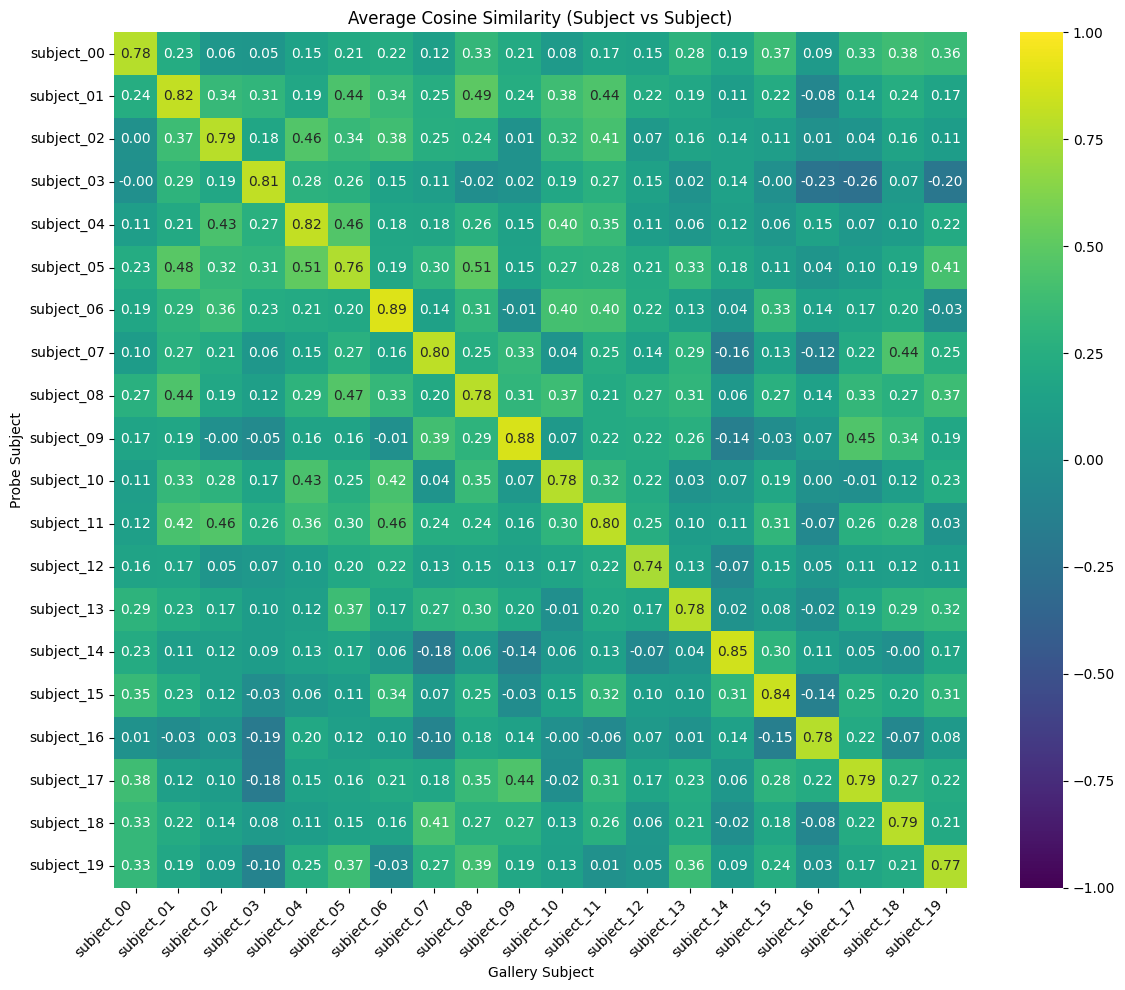

Plotting normalized confusion matrix for InceptionResnetV1-VGGFace2

:
['subject_00' 'subject_01' 'subject_02' 'subject_03' 'subject_04'
 'subject_05' 'subject_06' 'subject_07' 'subject_08' 'subject_09'
 'subject_10' 'subject_11' 'subject_12' 'subject_13' 'subject_14'
 'subject_15' 'subject_16' 'subject_17' 'subject_18' 'subject_19']

=== NORMALIZED CONFUSION MATRIX: InceptionResnetV1-VGGFace2 ===


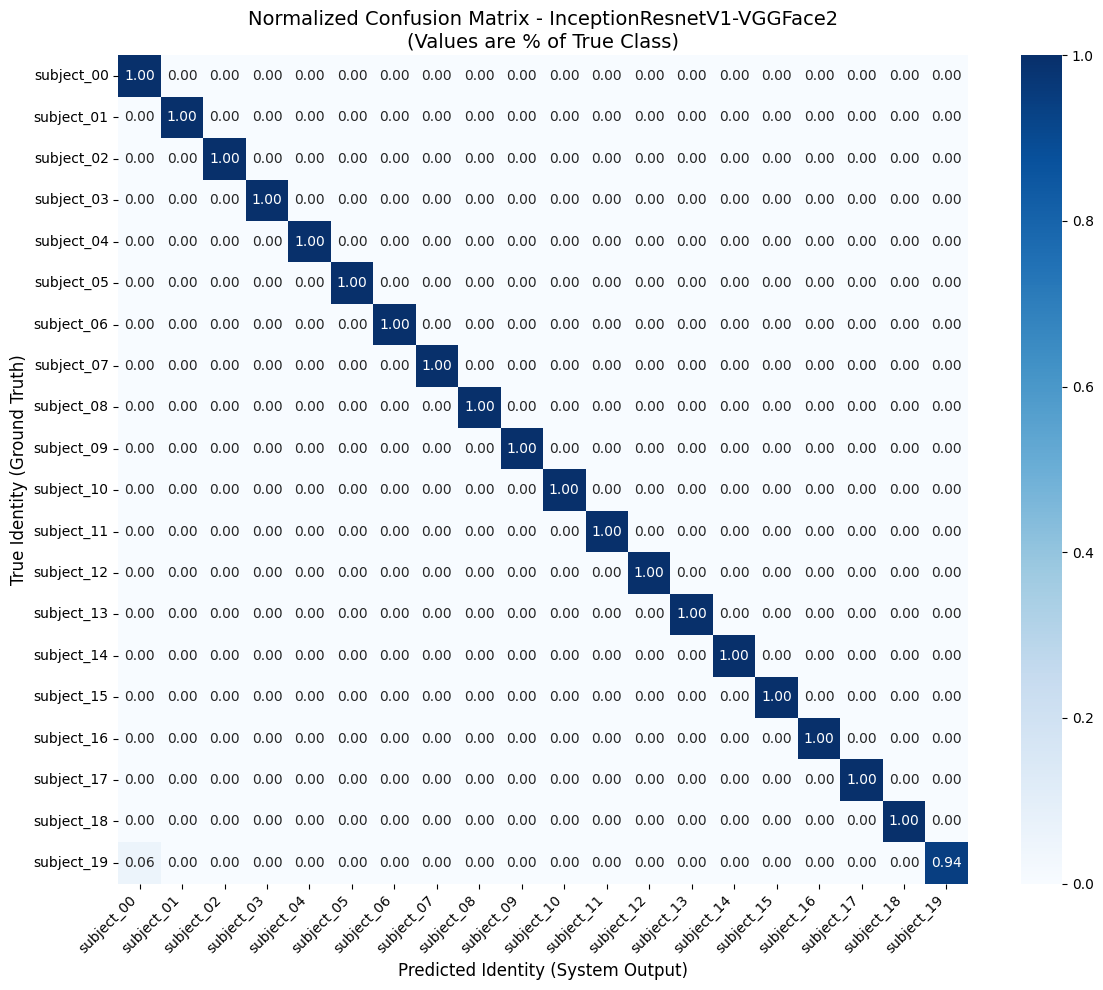


Evaluating Model: InceptionResnetV1-CASIA...
Extracting probe features for model:  InceptionResnetV1-CASIA

Results for InceptionResnetV1-CASIA:

Rank-1 Identification Accuracy: 99.444%

\Similarity matrix averaged for each test subject using InceptionResnetV1-CASIA

:
['subject_00' 'subject_01' 'subject_02' 'subject_03' 'subject_04'
 'subject_05' 'subject_06' 'subject_07' 'subject_08' 'subject_09'
 'subject_10' 'subject_11' 'subject_12' 'subject_13' 'subject_14'
 'subject_15' 'subject_16' 'subject_17' 'subject_18' 'subject_19']
Computing average similarity per subject...


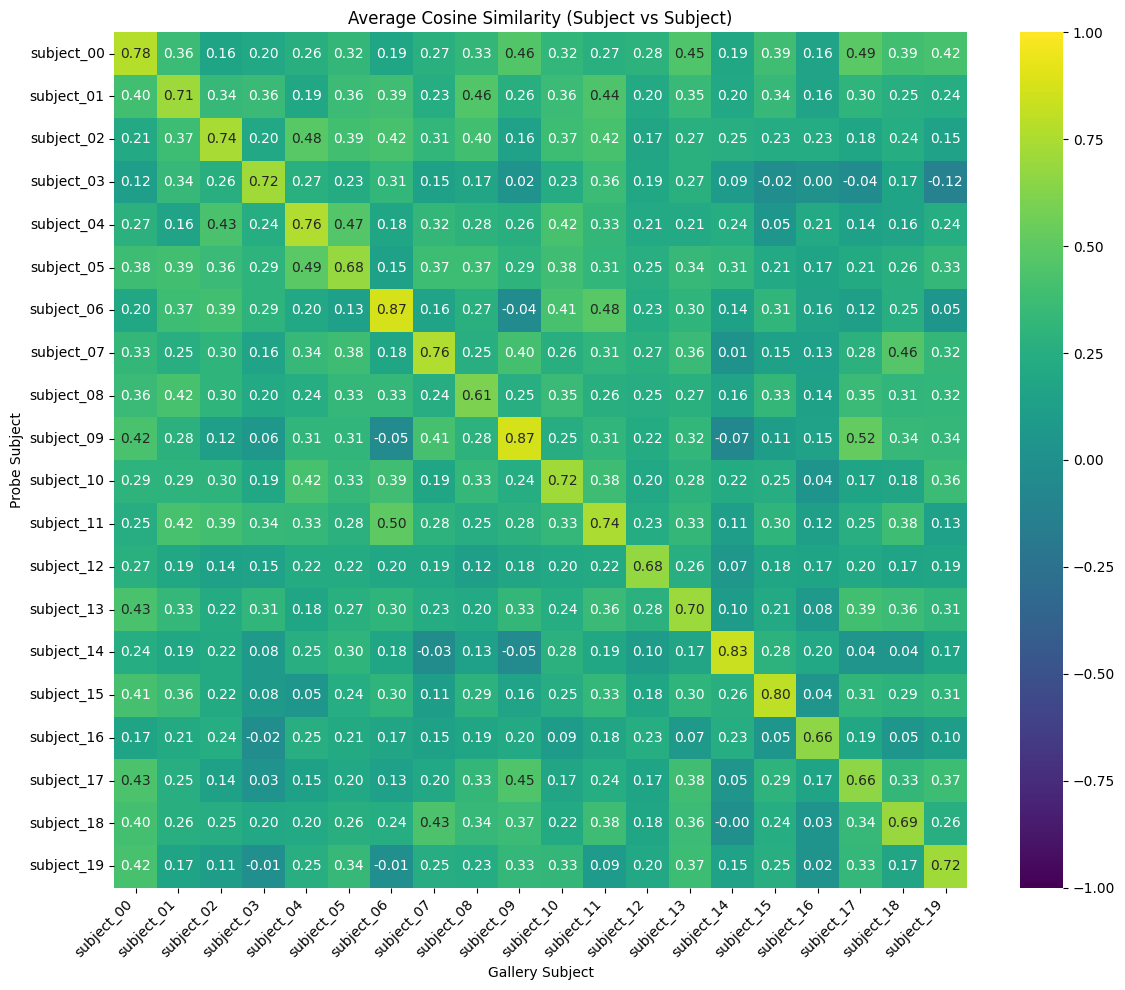

Plotting normalized confusion matrix for InceptionResnetV1-CASIA

:
['subject_00' 'subject_01' 'subject_02' 'subject_03' 'subject_04'
 'subject_05' 'subject_06' 'subject_07' 'subject_08' 'subject_09'
 'subject_10' 'subject_11' 'subject_12' 'subject_13' 'subject_14'
 'subject_15' 'subject_16' 'subject_17' 'subject_18' 'subject_19']

=== NORMALIZED CONFUSION MATRIX: InceptionResnetV1-CASIA ===


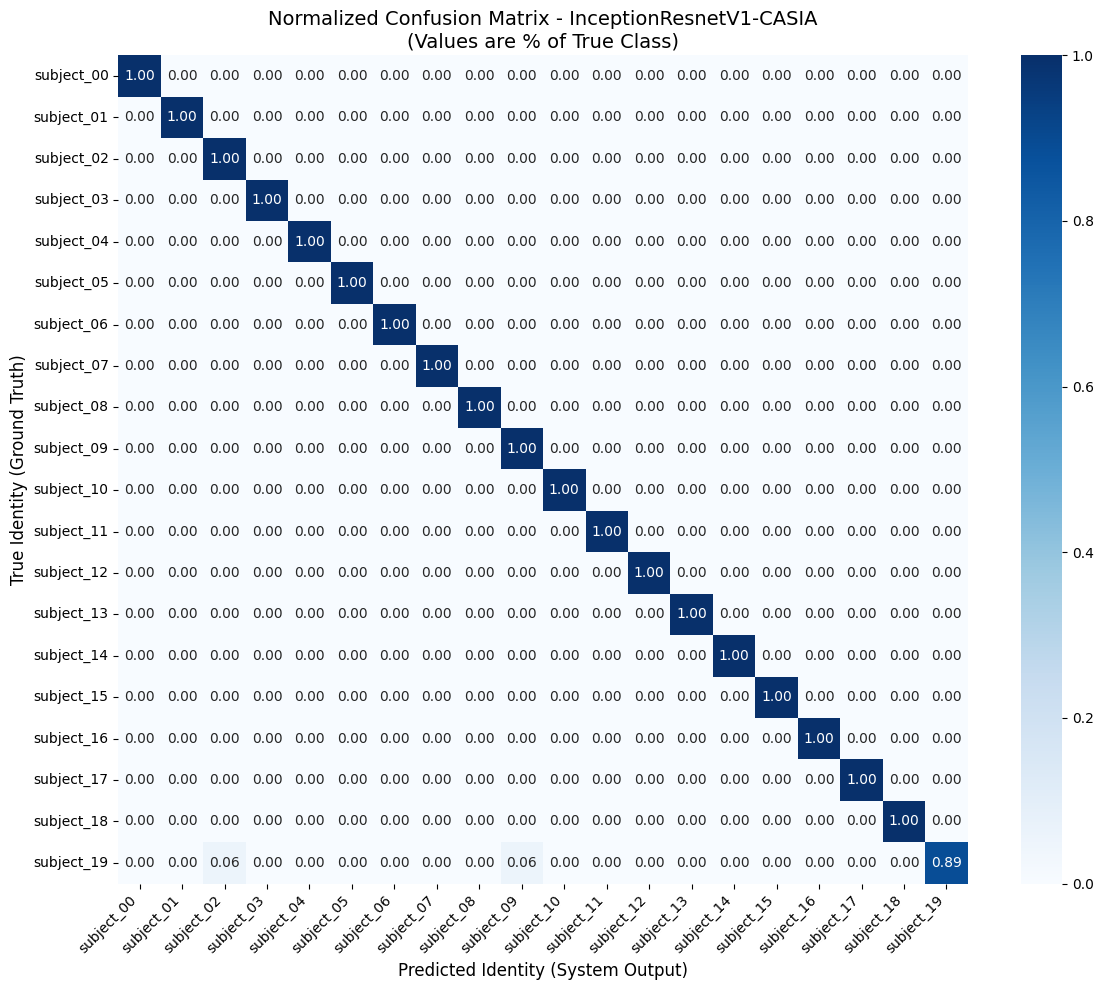


Evaluating Model: ArcFace...
Extracting probe features for model:  ArcFace

Results for ArcFace:

Rank-1 Identification Accuracy: 98.889%

\Similarity matrix averaged for each test subject using ArcFace

:
['subject_00' 'subject_01' 'subject_02' 'subject_03' 'subject_04'
 'subject_05' 'subject_06' 'subject_07' 'subject_08' 'subject_09'
 'subject_10' 'subject_11' 'subject_12' 'subject_13' 'subject_14'
 'subject_15' 'subject_16' 'subject_17' 'subject_18' 'subject_19']
Computing average similarity per subject...


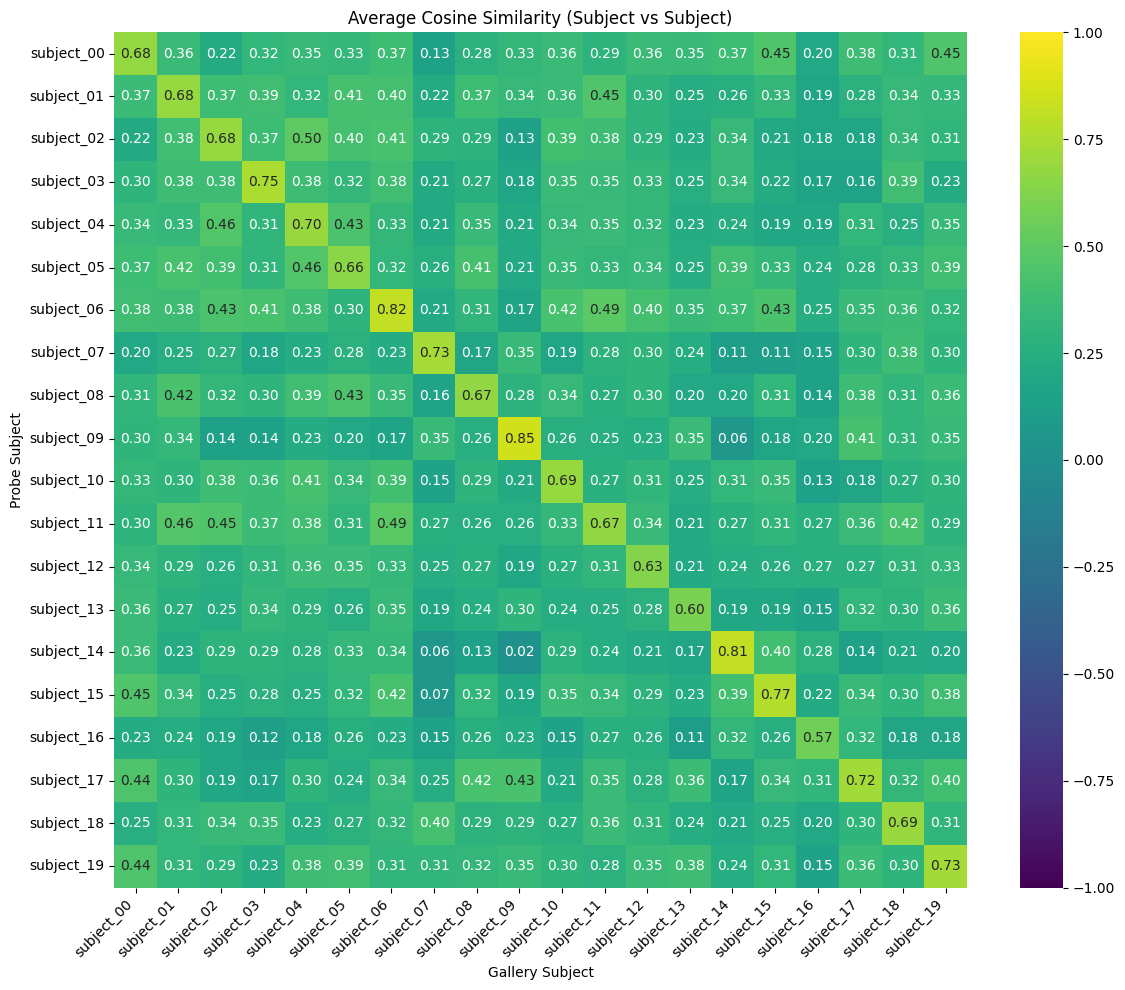

Plotting normalized confusion matrix for ArcFace

:
['subject_00' 'subject_01' 'subject_02' 'subject_03' 'subject_04'
 'subject_05' 'subject_06' 'subject_07' 'subject_08' 'subject_09'
 'subject_10' 'subject_11' 'subject_12' 'subject_13' 'subject_14'
 'subject_15' 'subject_16' 'subject_17' 'subject_18' 'subject_19']

=== NORMALIZED CONFUSION MATRIX: ArcFace ===


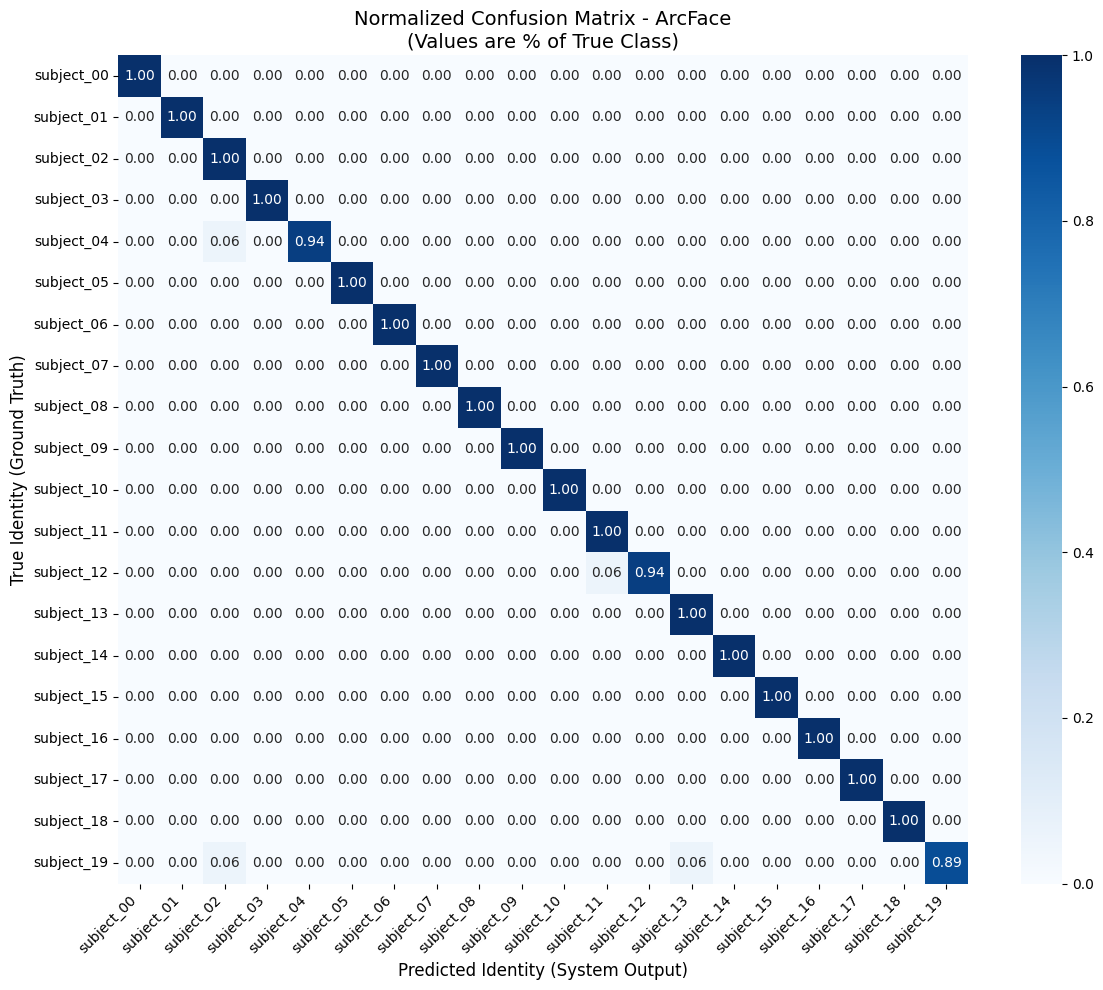


Evaluating Model: Facenet512...
Extracting probe features for model:  Facenet512

Results for Facenet512:

Rank-1 Identification Accuracy: 96.944%

\Similarity matrix averaged for each test subject using Facenet512

:
['subject_00' 'subject_01' 'subject_02' 'subject_03' 'subject_04'
 'subject_05' 'subject_06' 'subject_07' 'subject_08' 'subject_09'
 'subject_10' 'subject_11' 'subject_12' 'subject_13' 'subject_14'
 'subject_15' 'subject_16' 'subject_17' 'subject_18' 'subject_19']
Computing average similarity per subject...


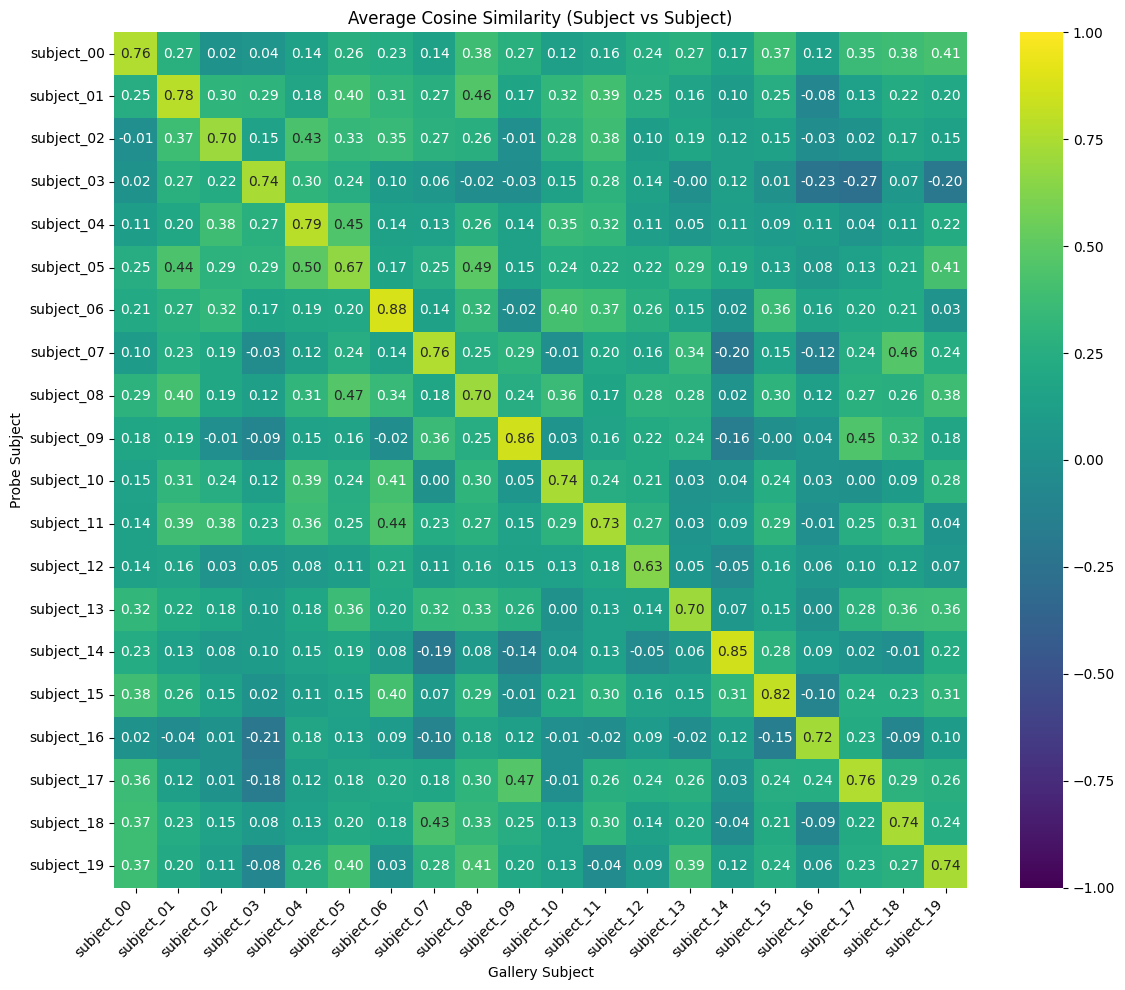

Plotting normalized confusion matrix for Facenet512

:
['subject_00' 'subject_01' 'subject_02' 'subject_03' 'subject_04'
 'subject_05' 'subject_06' 'subject_07' 'subject_08' 'subject_09'
 'subject_10' 'subject_11' 'subject_12' 'subject_13' 'subject_14'
 'subject_15' 'subject_16' 'subject_17' 'subject_18' 'subject_19']

=== NORMALIZED CONFUSION MATRIX: Facenet512 ===


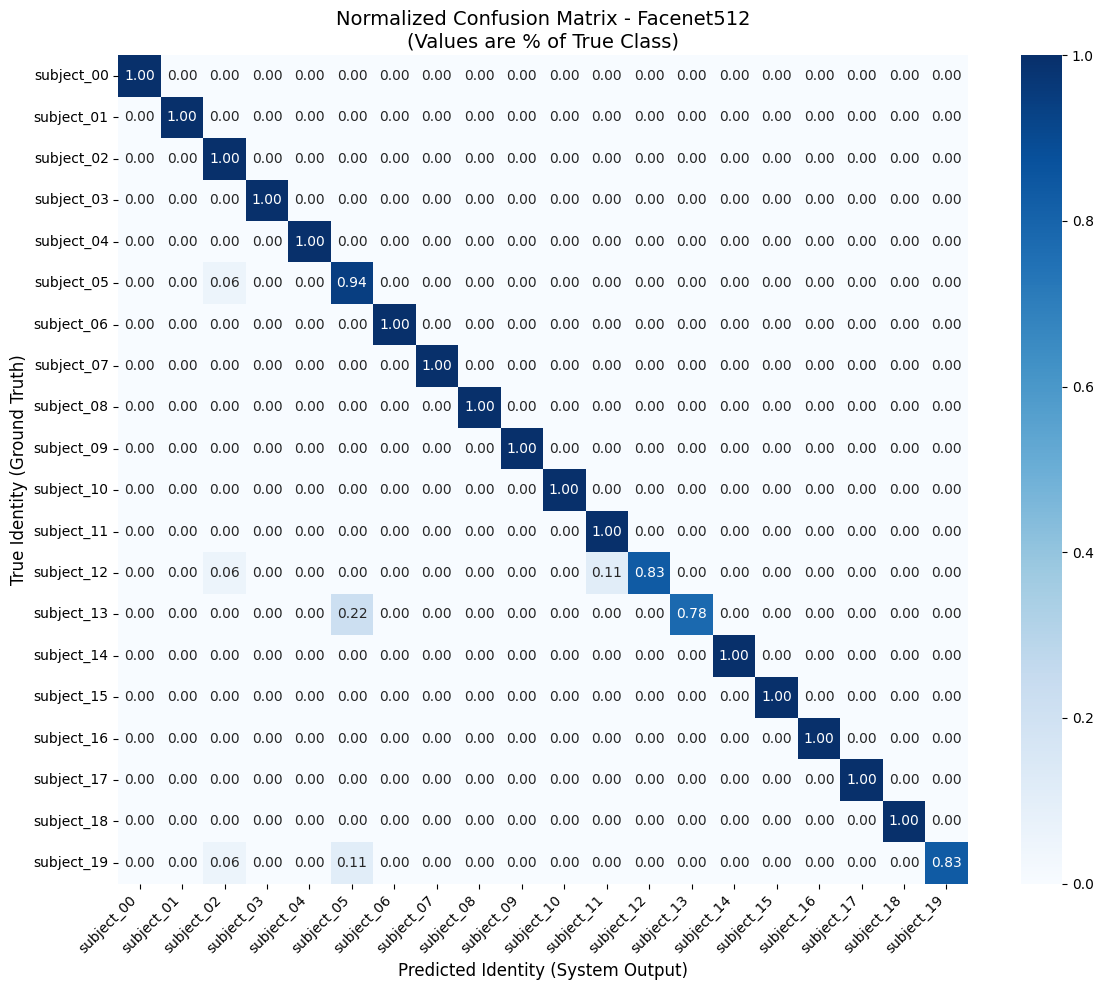


Evaluating Model: VGG-Face...
Extracting probe features for model:  VGG-Face

Results for VGG-Face:

Rank-1 Identification Accuracy: 94.167%

\Similarity matrix averaged for each test subject using VGG-Face

:
['subject_00' 'subject_01' 'subject_02' 'subject_03' 'subject_04'
 'subject_05' 'subject_06' 'subject_07' 'subject_08' 'subject_09'
 'subject_10' 'subject_11' 'subject_12' 'subject_13' 'subject_14'
 'subject_15' 'subject_16' 'subject_17' 'subject_18' 'subject_19']
Computing average similarity per subject...


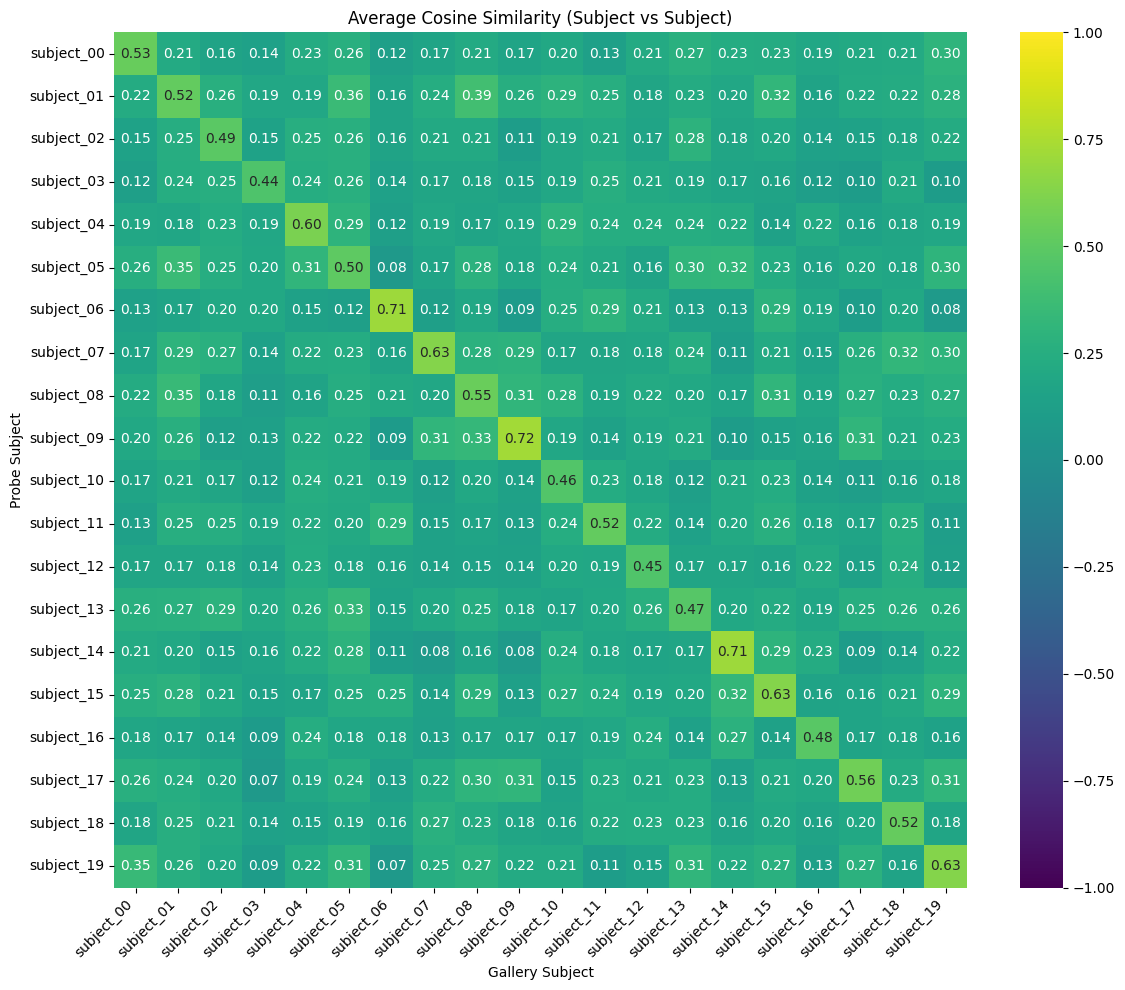

Plotting normalized confusion matrix for VGG-Face

:
['subject_00' 'subject_01' 'subject_02' 'subject_03' 'subject_04'
 'subject_05' 'subject_06' 'subject_07' 'subject_08' 'subject_09'
 'subject_10' 'subject_11' 'subject_12' 'subject_13' 'subject_14'
 'subject_15' 'subject_16' 'subject_17' 'subject_18' 'subject_19']

=== NORMALIZED CONFUSION MATRIX: VGG-Face ===


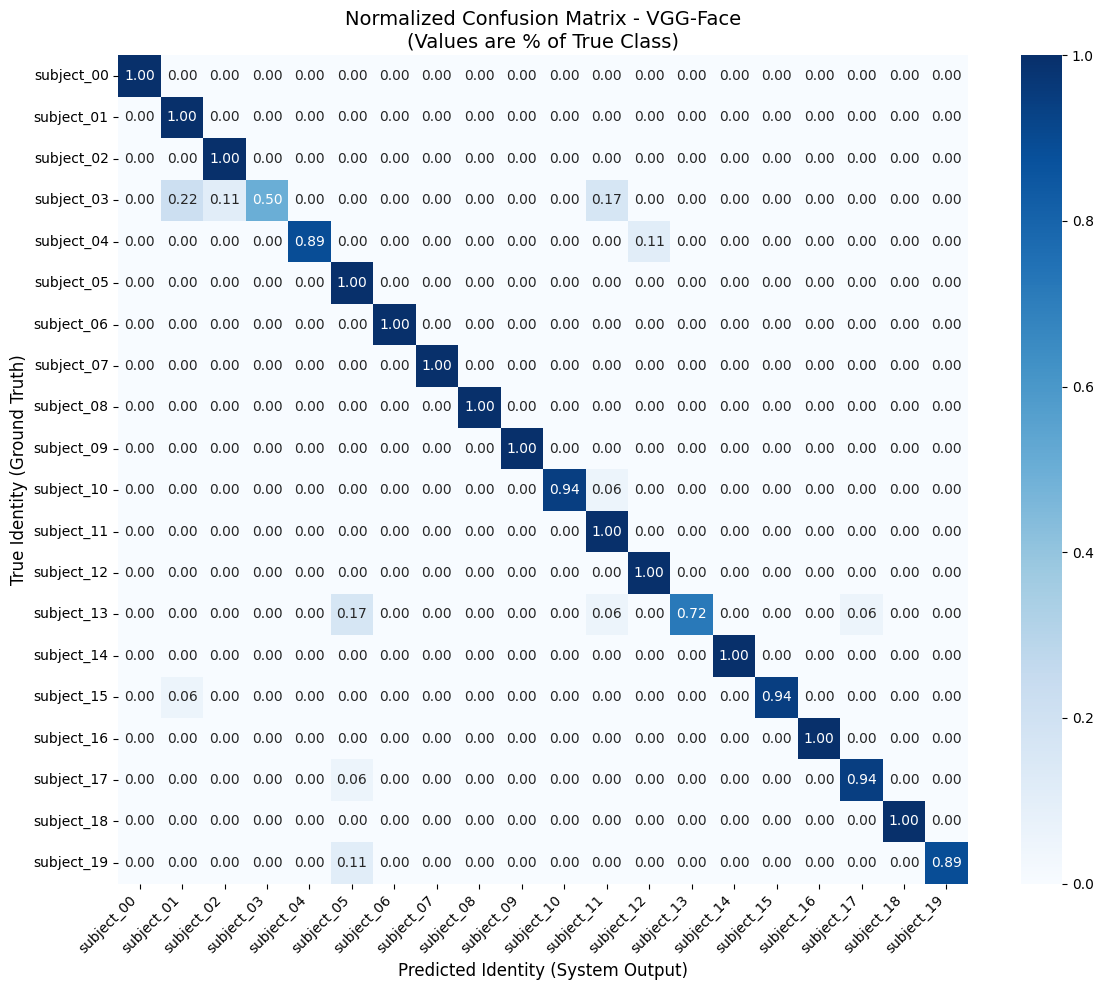


Evaluating Model: GhostFaceNet...
Extracting probe features for model:  GhostFaceNet

Results for GhostFaceNet:

Rank-1 Identification Accuracy: 97.222%

\Similarity matrix averaged for each test subject using GhostFaceNet

:
['subject_00' 'subject_01' 'subject_02' 'subject_03' 'subject_04'
 'subject_05' 'subject_06' 'subject_07' 'subject_08' 'subject_09'
 'subject_10' 'subject_11' 'subject_12' 'subject_13' 'subject_14'
 'subject_15' 'subject_16' 'subject_17' 'subject_18' 'subject_19']
Computing average similarity per subject...


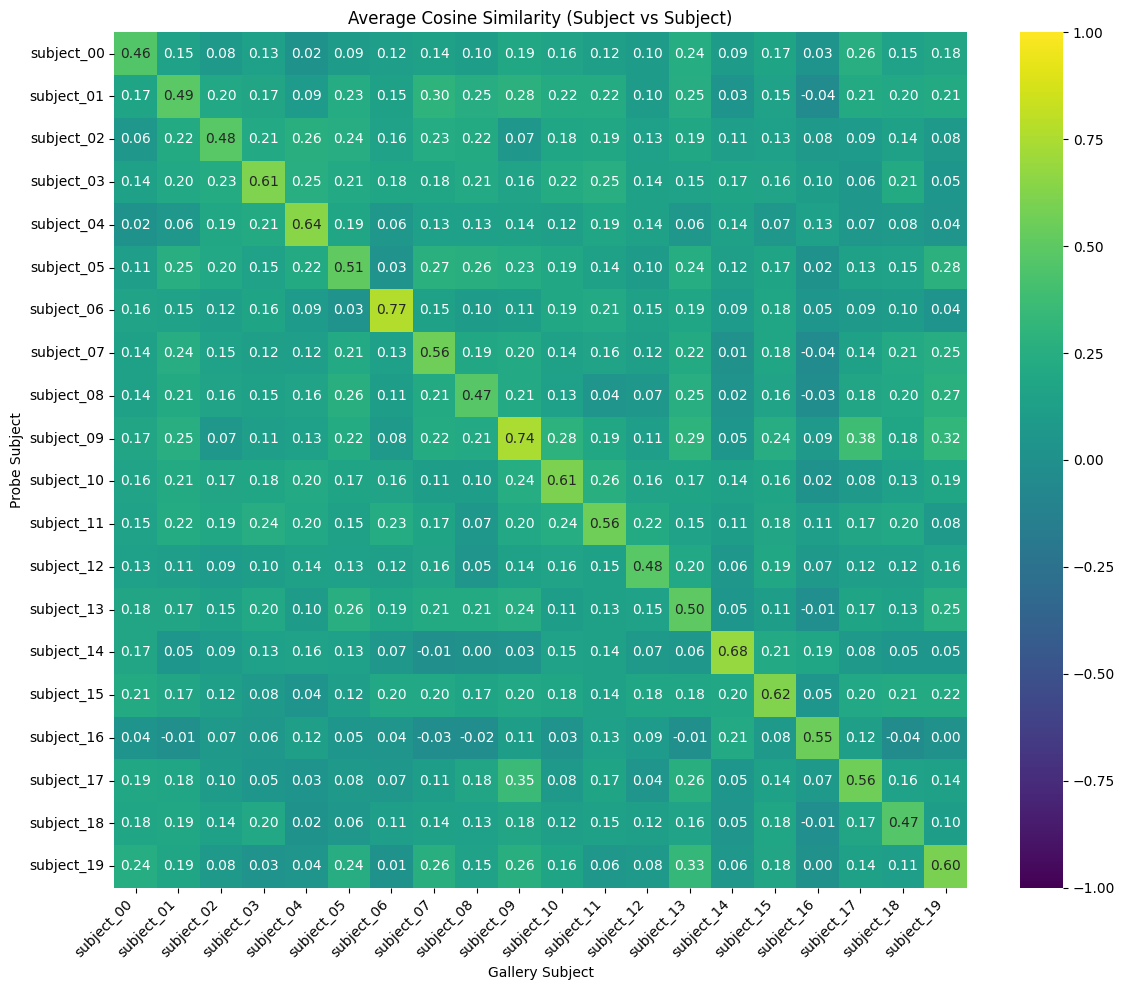

Plotting normalized confusion matrix for GhostFaceNet

:
['subject_00' 'subject_01' 'subject_02' 'subject_03' 'subject_04'
 'subject_05' 'subject_06' 'subject_07' 'subject_08' 'subject_09'
 'subject_10' 'subject_11' 'subject_12' 'subject_13' 'subject_14'
 'subject_15' 'subject_16' 'subject_17' 'subject_18' 'subject_19']

=== NORMALIZED CONFUSION MATRIX: GhostFaceNet ===


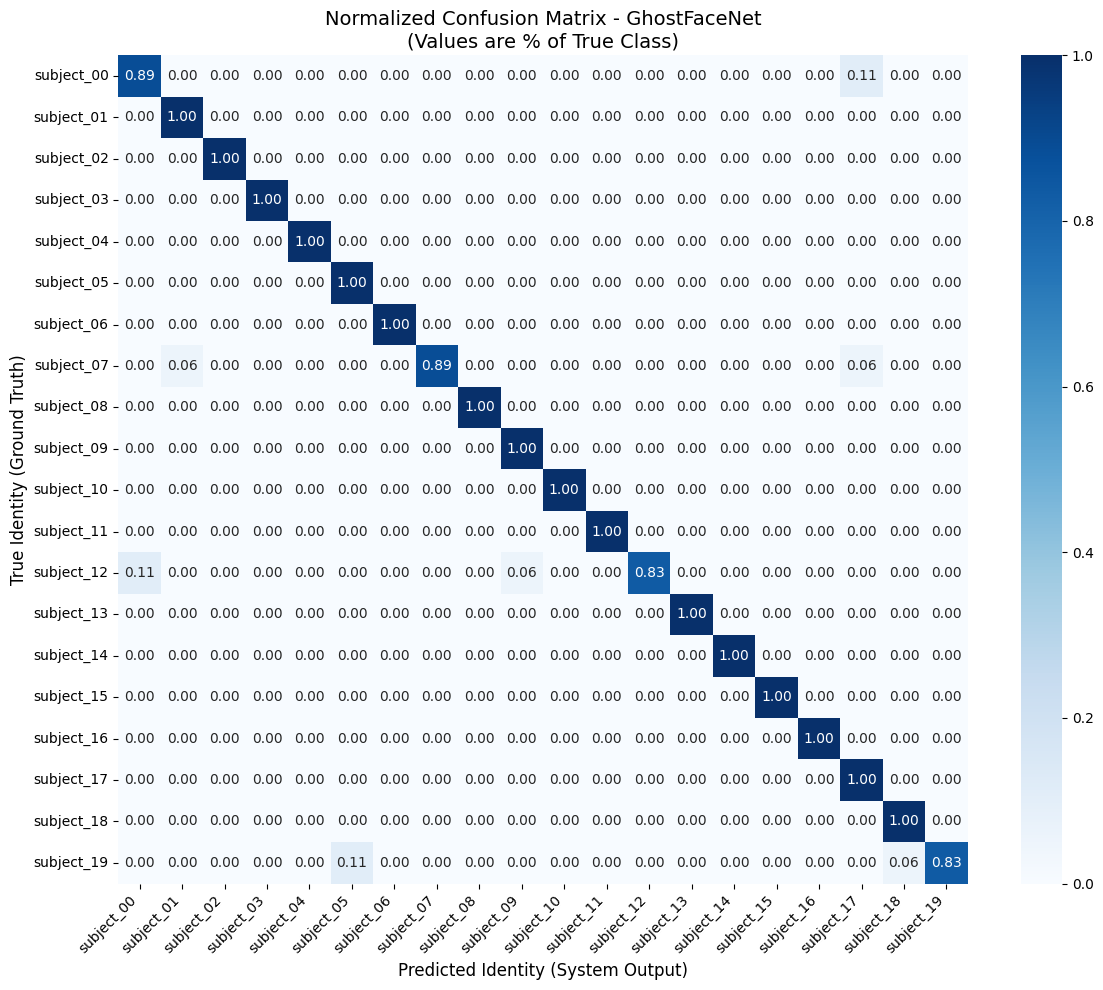


Evaluating Model: SFace...
Extracting probe features for model:  SFace

Results for SFace:

Rank-1 Identification Accuracy: 97.222%

\Similarity matrix averaged for each test subject using SFace

:
['subject_00' 'subject_01' 'subject_02' 'subject_03' 'subject_04'
 'subject_05' 'subject_06' 'subject_07' 'subject_08' 'subject_09'
 'subject_10' 'subject_11' 'subject_12' 'subject_13' 'subject_14'
 'subject_15' 'subject_16' 'subject_17' 'subject_18' 'subject_19']
Computing average similarity per subject...


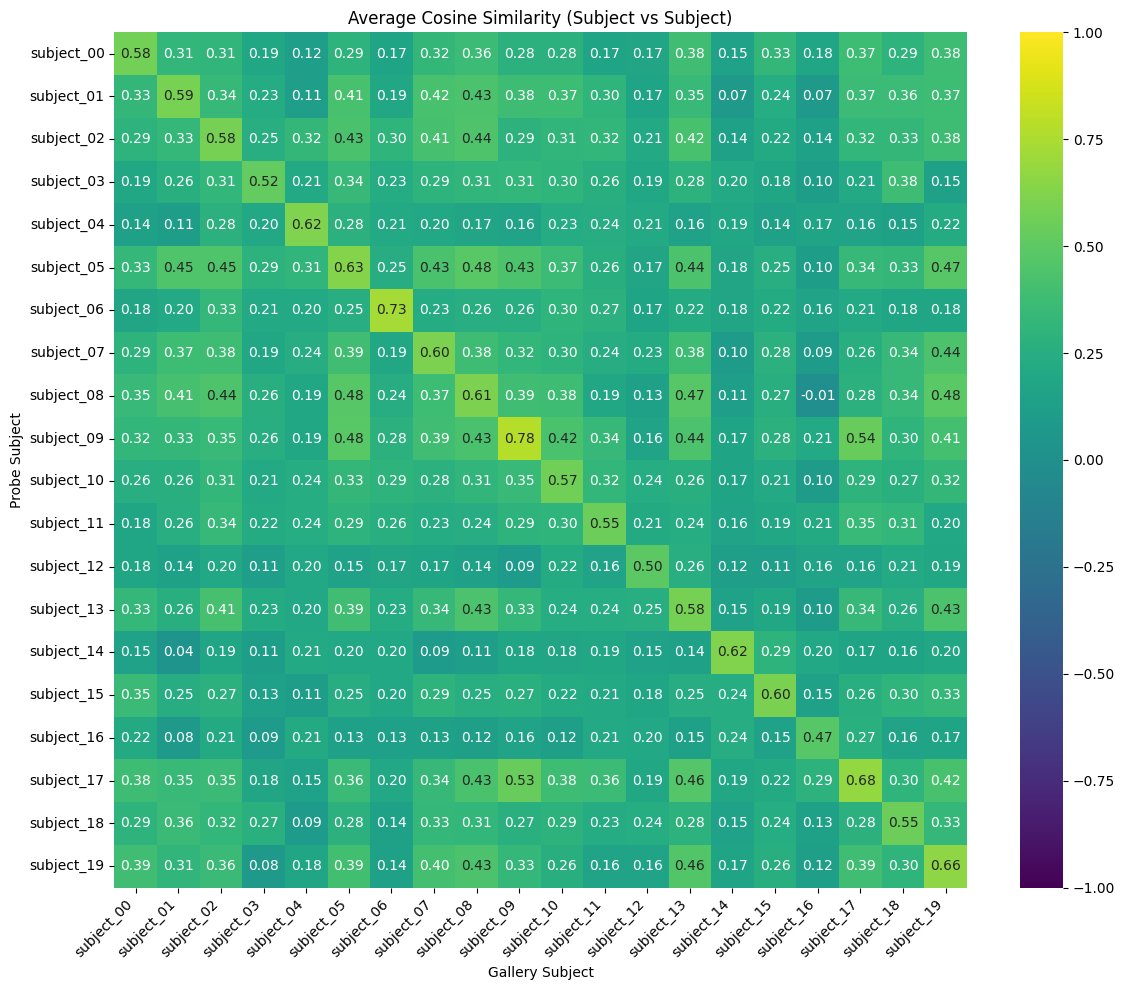

Plotting normalized confusion matrix for SFace

:
['subject_00' 'subject_01' 'subject_02' 'subject_03' 'subject_04'
 'subject_05' 'subject_06' 'subject_07' 'subject_08' 'subject_09'
 'subject_10' 'subject_11' 'subject_12' 'subject_13' 'subject_14'
 'subject_15' 'subject_16' 'subject_17' 'subject_18' 'subject_19']

=== NORMALIZED CONFUSION MATRIX: SFace ===


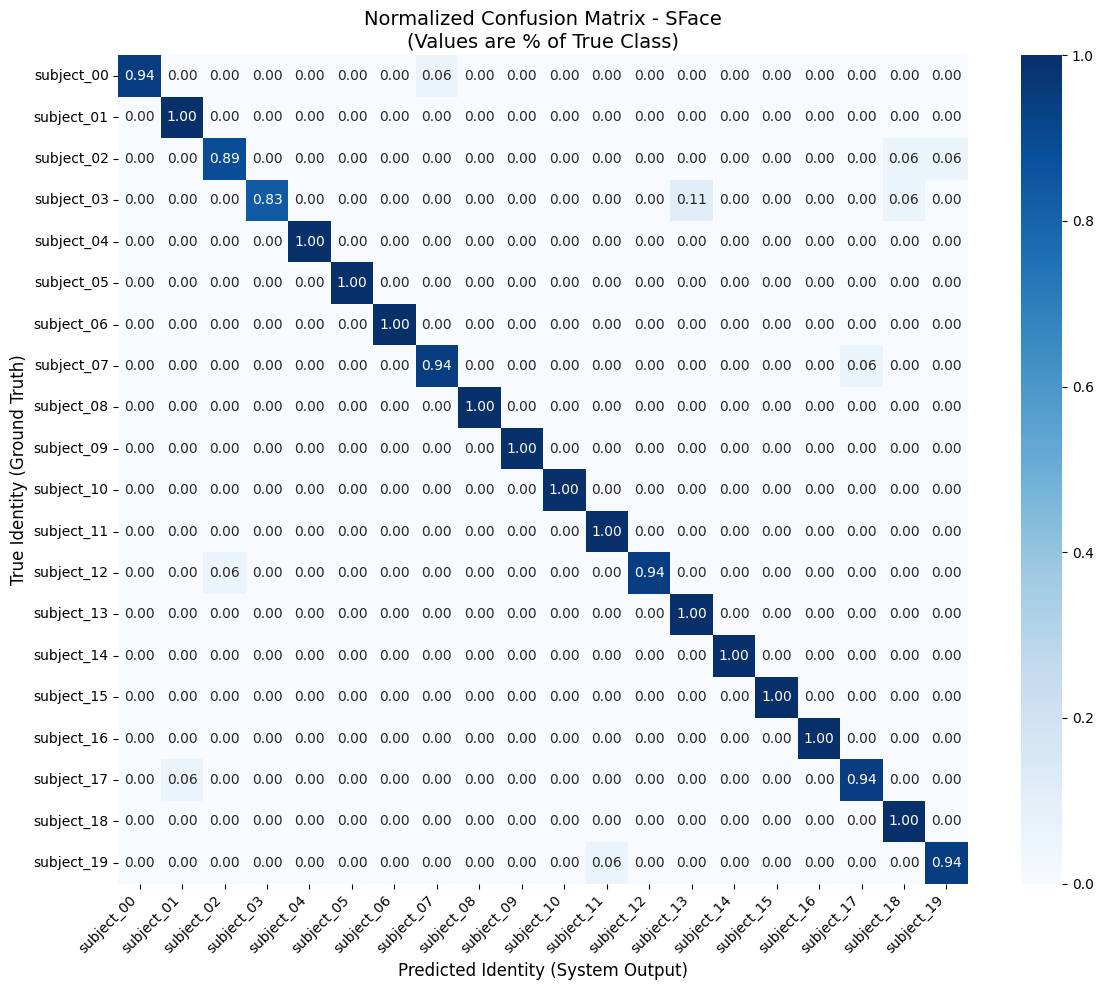



                    Results Summary

Best Model for Rank-1 Identification Accuracy: InceptionResnetV1-VGGFace2 with Accuracy: 0.9972222222222222


The best model from MLP classification evaluation is Facenet512
The best model from similarity-based identification evaluation is InceptionResnetV1-VGGFace2




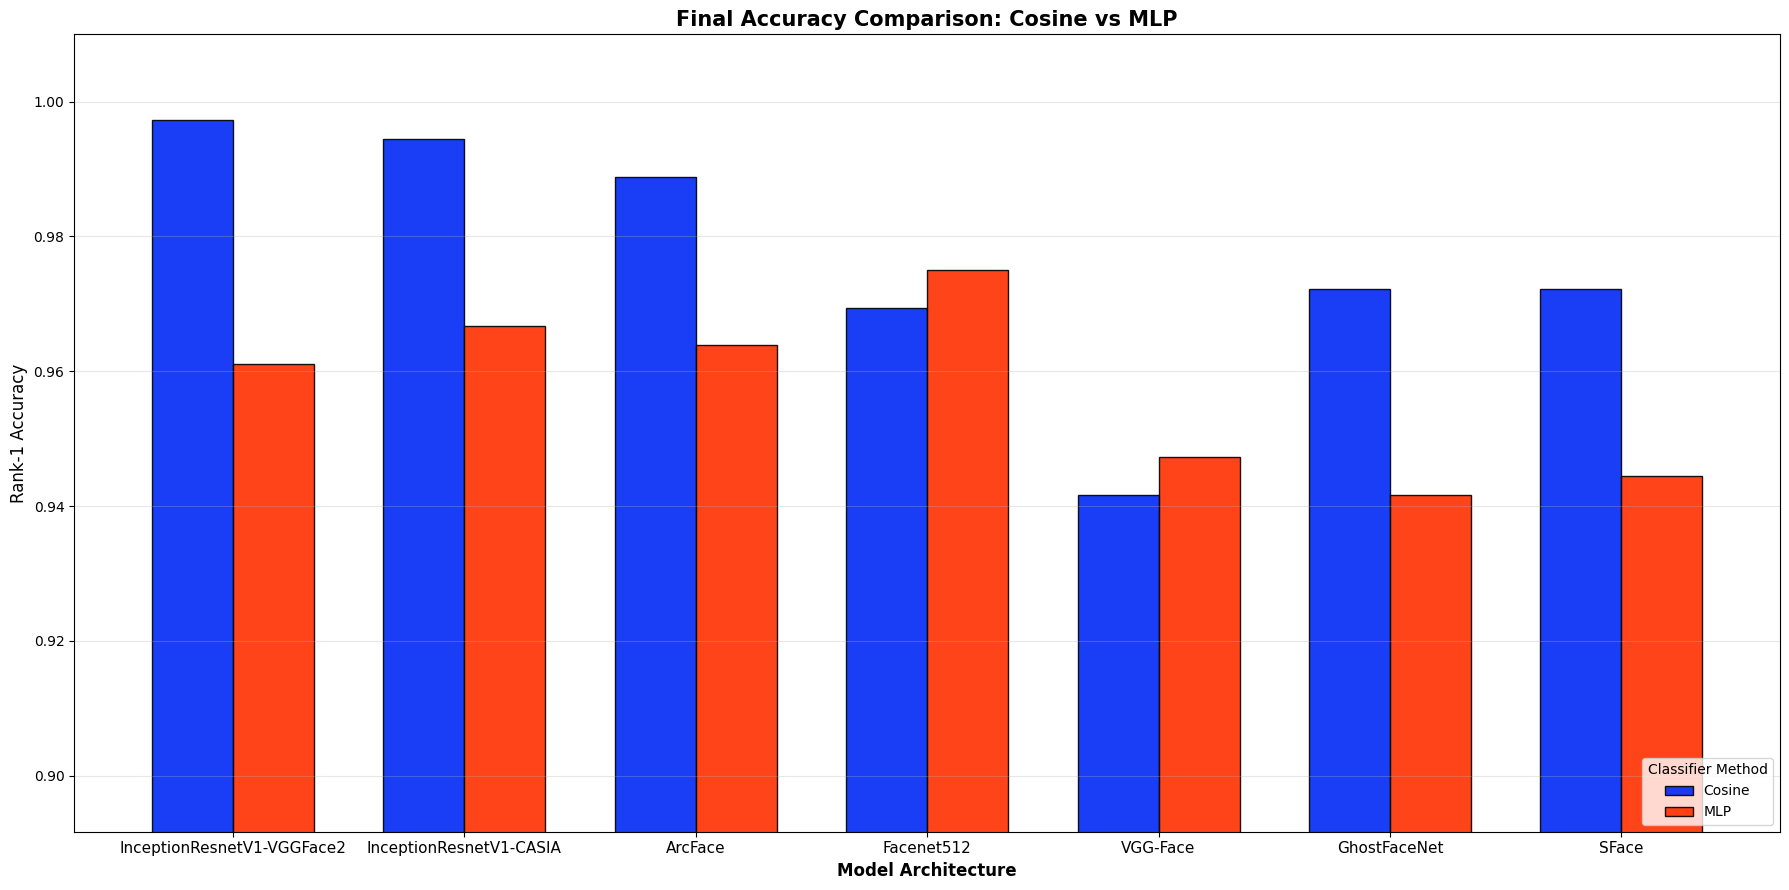

In [63]:
# Rank-1 identification benchmark with cosine similarity.
# Selection metric: Rank-1 accuracy estimated with 4-fold CV on the GALLERY.
# The probe Rank-1 is computed for reference only (probes = untouched test set).
y_gallery = processed_train.target
probe_labels = processed_test.target
gallery_names = target_names

if feature_extractor_evaluation_flag:
    print(f"{'='*60}\nRANK-1 IDENTIFICATION BENCHMARK ACROSS ALL MODELS\n{'='*60}")
    for model_name in model_candidates:
        X_gallery, X_probe = embeddings_cache[model_name]
        cv_acc, cv_std = utils.cross_validated_rank1(X_gallery, y_gallery, k_folds=4)
        sim_matrix = np.dot(X_probe, X_gallery.T)
        predicted_labels = y_gallery[np.argmax(sim_matrix, axis=1)]
        probe_acc = accuracy_score(probe_labels, predicted_labels)
        evaluation_results["rank1_cv_acc"].append(cv_acc)
        evaluation_results["rank1_probe_acc"].append(probe_acc)
        print(f"\n{model_name}: Rank-1 CV (gallery) = {cv_acc*100:.2f}% (+/- {cv_std*100:.2f}) | "
              f"Rank-1 probes = {probe_acc*100:.2f}%")
        utils.plot_subject_average_similarity(sim_matrix, probe_labels, y_gallery, target_names)
        utils.plot_normalized_confusion_matrix(probe_labels, predicted_labels, target_names, model_name)

    similarity_best_model_name = model_candidates[int(np.argmax(evaluation_results["rank1_cv_acc"]))]
    print(f"\n{'='*75}\nBest model for cosine Rank-1 (gallery CV): {similarity_best_model_name}")
    print(f"Best model for MLP classification (gallery CV): {mlp_best_model_name}\n{'='*75}")
    # The operational system matches embeddings with cosine similarity -> the Rank-1 winner is selected
    best_model_name = similarity_best_model_name

    utils.plot_evaluation_results(model_candidates, {
        "MLP - gallery 5-fold CV": evaluation_results["mlp_cv_acc"],
        "MLP - probes (reference)": evaluation_results["mlp_probe_acc"],
        "Cosine Rank-1 - gallery 4-fold CV": evaluation_results["rank1_cv_acc"],
        "Cosine Rank-1 - probes (reference)": evaluation_results["rank1_probe_acc"],
    }, title="Feature extractor comparison")
    best_X_gallery, best_probe_embs_norm = embeddings_cache[best_model_name]
else:
    X_train_raw = utils.preprocess_and_embed(processed_train, best_model_name, device, batch_size, verbose=False)
    X_test_raw = utils.preprocess_and_embed(processed_test, best_model_name, device, batch_size, verbose=False)
    best_X_gallery = normalize(X_train_raw, norm='l2')
    best_probe_embs_norm = normalize(X_test_raw, norm='l2')

# Selected model: gallery templates (also used for threshold tuning) and probe embeddings
best_y_gallery = y_gallery
best_X_train_norm, best_y_train = best_X_gallery, best_y_gallery
best_sim_matrix = np.dot(best_probe_embs_norm, best_X_gallery.T)
best_predicted_labels = best_y_gallery[np.argmax(best_sim_matrix, axis=1)]
best_r1_accuracy = accuracy_score(probe_labels, best_predicted_labels)
print(f"\nSelected model: {best_model_name} | Rank-1 accuracy on probes (test set): {best_r1_accuracy*100:.2f}%")

if not feature_extractor_evaluation_flag:
    utils.plot_subject_average_similarity(best_sim_matrix, probe_labels, best_y_gallery, target_names)
    utils.plot_normalized_confusion_matrix(probe_labels, best_predicted_labels, target_names, best_model_name)

## Saving Gallery Embeddings

After the best feature extractor, the embeddings can be stored

In [64]:
gallery_name = "gallery.npy"
database_dir = "System_Database/gallery"

# Create gallery file
print(f"The model selected for embedding extraction is: {best_model_name}")
utils.create_gallery(best_X_gallery, best_y_gallery, target_names, filename=gallery_name, database_dir=database_dir, verbose=True)

if check_embeddings_flag:
    utils.check_gallery_content(filename=gallery_name, database_dir=database_dir, n_samples=160)

The model selected for embedding extraction is: InceptionResnetV1-VGGFace2
Creating Gallery at 'System_Database/gallery\gallery.npy'...
Success! Saved 160 embeddings.
Gallery Shape: (160, 512)
File Size: 322.59 KB

--- Checking Gallery File: gallery.npy ---
Embeddings shape: (160, 512)
Labels shape:     (160,)
Names shape:      (20,)

Sample Data (First 160 entries):
 Entry 0: Label=0 (subject_00) | Vector[:5]=[-0.0385916  -0.05370542 -0.02084136  0.01848138  0.03034582]...
 Entry 1: Label=0 (subject_00) | Vector[:5]=[-0.06299293 -0.0332313  -0.01584092 -0.01819308  0.01705009]...
 Entry 2: Label=0 (subject_00) | Vector[:5]=[-0.07133303 -0.0199239  -0.01995778 -0.01906126  0.01885777]...
 Entry 3: Label=0 (subject_00) | Vector[:5]=[-0.0446426  -0.00984363 -0.01390439 -0.00447736  0.04776322]...
 Entry 4: Label=0 (subject_00) | Vector[:5]=[-0.02285031 -0.0386198  -0.00598324 -0.03265956  0.02131639]...
 Entry 5: Label=0 (subject_00) | Vector[:5]=[-0.05763726 -0.03456903 -0.02939394  0.0

## Identification & Verification with Base Thresholds

Once the base embeddings (coming from the gallery part of the dataseet) have been successfully saved inside the system database, phase 3 and phase 4 are the next: user verification and user identification. For now it will be still used a base value (0.5) for $\tau_i$ and $\tau_v$

Probes will be used to assess the performences of the system.

For the threshold tuning will be used a validation set derived from the gallery samples 

In [65]:
n_samples = 25       
random_seed = 42   
np.random.seed(random_seed)
random.seed(random_seed)

base_Ti = 0.50
base_Tv = 0.50

print(f"Verification Threshold (Tv): {base_Tv}")
print(f"Identification Threshold (Ti): {base_Ti}\n")

# Load embedding from gallery
gal_embs, gal_labels, gal_names = utils.load_gallery(filename=gallery_name, gallery_path=database_dir)

# FAR, FFR, FNIR are computed on the probe set (against the gallery)
far_verification, frr_verification = th_tuning.compute_far_frr_verification_on_probes(base_Tv, best_probe_embs_norm, probe_labels, gal_embs, gal_labels)
fnir = th_tuning.compute_fnir_identification_on_probes(base_Ti, best_probe_embs_norm, probe_labels, gal_embs, gal_labels, gal_names)
far_identification = th_tuning.compute_open_set_far_on_probes(threshold=base_Ti, probe_embs=best_probe_embs_norm, probe_labels=probe_labels, gal_embs=gal_embs, gal_labels=gal_labels, gal_names=processed_test.target_names)
    

Verification Threshold (Tv): 0.5
Identification Threshold (Ti): 0.5

CALCULATING FAR & FRR
Tv = 0.5000
--------------------------------------------------
Genuine Comparisons:  2880
False Rejects:        22
--> FRR:              0.7639%
--------------------------------------------------
Impostor Comparisons: 54720
False Accepts:        1305
--> FAR:              2.3849%

CALCULATING IDENTIFICATION METRICS (1:N)
Threshold (Ti) = 0.5
Total Probes: 360
Correct Identifications (DIR): 359
Misses (Unknown + Wrong ID):   1
--> Identification Rate (DIR): 99.72%
--> Miss Rate (FNIR):          0.28%

--- Running Open Set Simulation (Ti=0.5000) ---
Ti=0.5000:
  Total Impostor Attempts: 360
  False Acceptances:       223
  --> Open Set FAR:        61.9444%


## Threshold Tuning $\tau_i$ & $\tau_v$

This section details the determination of optimal values for the identification threshold ($\tau_i$) and the verification threshold ($\tau_v$), aimed at implementing system requirements 3 and 4.

#### Methodology

1. Calibration Strategy Ideally, thresholds for open-set recognition are calibrated using a subject-disjoint validation set to simulate truly unknown impostors. However, given the limited dataset size, reserving subjects strictly for validation would critically reduce the gallery's class diversity.

Therefore, it has been adopted an image-disjoint strategy combined with K-Fold Cross-Validation:

- Validation Set Construction: The validation set consists of unseen images from all 20 subjects. During calibration, these validation images are strictly removed from the gallery embeddings to prevent data leakage.

- Cross-Validation: To ensure statistical robustness and prevent bias from specific data partitions, it has been implemented a Stratified K-Fold Cross-Validation strategy ($K=3$).

The dataset is partitioned into $K$ disjoint subsets (folds). In each iteration $k$ ($1 \dots 3$), $K-1$ folds form the temporary Gallery, while the remaining fold serves as the Validation Set (Probes). 

Stratification ensures consistent subject representation across all folds. This approach allows every image to serve as a validation sample exactly once.

2. Optimization Process. For each fold, the calibration is performed by computing specific similarity distributions tailored to the distinct nature of the two tasks:

- Similarity Computation. 
    Genuine Scores ($S_{gen}$): Derived from all pairs where the probe and gallery template belong to the same subject. These simulate authorized access attempts.
    
    All-Impostor Scores ($S_{all\_imp}$): For Verification tuning, it is computed the similarity between every probe and every gallery image of different identities (Image-to-Image). This dense distribution represents the standard 1:1 impostor scenario.
    
    Max-Impostor Scores ($S_{max\_imp}$): For Identification tuning, only the maximum similarity score each probe achieves against any incorrect identity is isolated. This worst-case metric simulates an open-set attack, posing the question: "Does the system mistake this probe for anyone in the gallery?"

- Threshold Selection: the threshold value $t$ has been swept from 0.0 to 1.0 (step size $\delta=0.001$) to analyze the trade-off between False Acceptance Rate (FAR) and False Rejection Rate (FRR).

Verification Threshold ($\tau_v$):  This serves as the operating point for 1:1 matching. Rather than optimizing for the Equal Error Rate (EER), which may permit an operationally insecure number of false acceptances, a strict security constraint is applied. The threshold is determined using the All-Impostor distribution ($S_{all\_imp}$) to enforce a maximum allowable FAR (e.g., $\leq 0.1\%$). This prioritizes system integrity over user convenience.

$$\tau_v = \min \{ t \mid FAR_{all}(t) \leq \text{desired\_far} \}$$

Identification Threshold ($\tau_i$):  This acts as the strict gatekeeper for 1:N search. Because identification selects the best match from the entire gallery, the risk of false positives is amplified. A strict threshold is selected using the Max-Impostor distribution ($S_{max\_imp}$) to constrain the Open-Set FAR to a high-security limit..

$$\tau_i = \min \{ t \mid FAR_{max}(t) \leq \text{desired\_far} \}$$

Final Determination. The final system thresholds are derived by averaging the optimal values obtained across all $K$ folds to ensure stability:

$$\tau_{final} = \frac{1}{K} \sum_{k=1}^{K} \tau^{(k)}$$

The standard deviation is also computed to assess the stability of the calibration across different data partitions.

CALCULATING FAR & FRR
Tv = 0.6010
--------------------------------------------------
Genuine Comparisons:  282
False Rejects:        0
--> FRR:              0.0000%
--------------------------------------------------
Impostor Comparisons: 5442
False Accepts:        21
--> FAR:              0.3859%

CALCULATING IDENTIFICATION METRICS (1:N)
Threshold (Ti) = 0.6880000000000001
Total Probes: 54
Correct Identifications (DIR): 54
Misses (Unknown + Wrong ID):   0
--> Identification Rate (DIR): 100.00%
--> Miss Rate (FNIR):          0.00%

--- Running Open Set Simulation (Ti=0.6880) ---
Ti=0.6880:
  Total Impostor Attempts: 54
  False Acceptances:       0
  --> Open Set FAR:        0.0000%
CALCULATING FAR & FRR
Tv = 0.6020
--------------------------------------------------
Genuine Comparisons:  279
False Rejects:        3
--> FRR:              1.0753%
--------------------------------------------------
Impostor Comparisons: 5392
False Accepts:        19
--> FAR:              0.3524%

CALCULATING

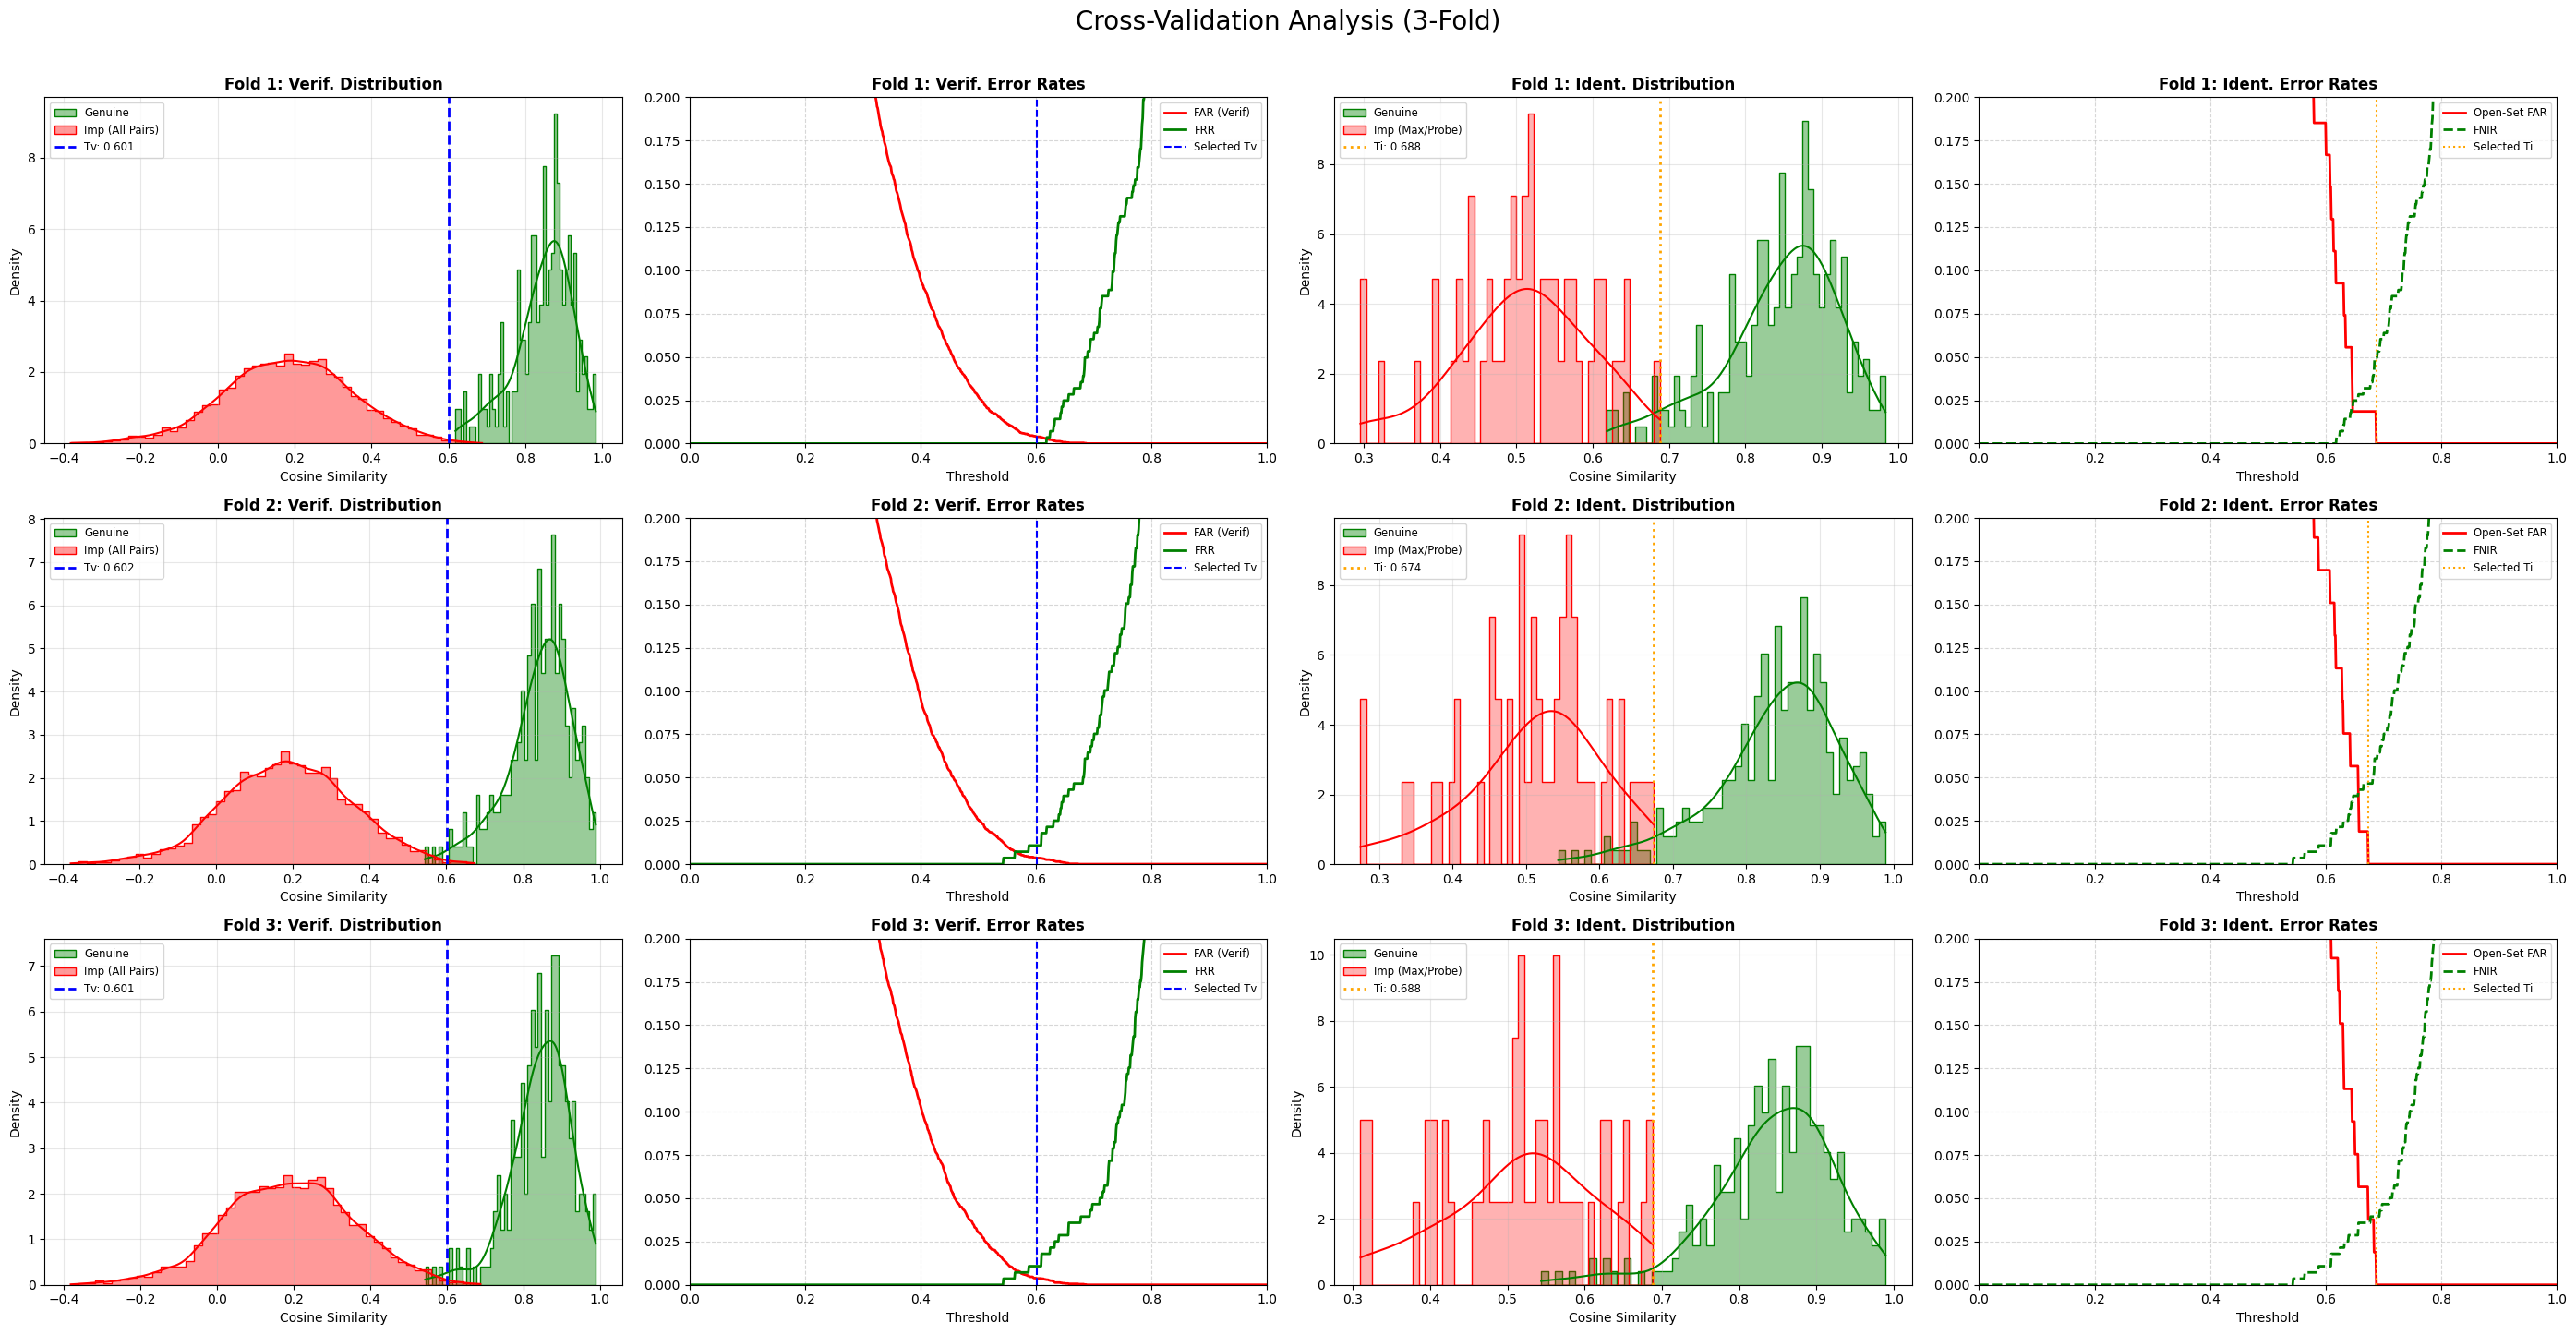


   CROSS-VALIDATION SUMMARY (Average across 3 folds)
Metric                         | Average    | Std Dev   
------------------------------------------------------------
Verification FAR (Tv)          | 0.37%     | ±0.01%
Verification FRR (Tv)          | 0.72%     | ±0.51%
------------------------------------------------------------
Identification Miss (FNIR)     | 0.00%     | ±0.00%
Open-Set FAR (Ti)              | 0.00%     | ±0.00%
Thresold tuning using K-FOLD cross-validation for validatiom:
K-FOLD RESULTS (Average of 3 runs)
Recommended Identification Threshold (Ti): 0.6833 with std: 0.0005
Recommended Verification Threshold (Tv): 0.6013 with std: 0.0066
CALCULATING FAR & FRR
Tv = 0.6020
--------------------------------------------------
Genuine Comparisons:  240
False Rejects:        0
--> FRR:              0.0000%
--------------------------------------------------
Impostor Comparisons: 4560
False Accepts:        16
--> FAR:              0.3509%

CALCULATING IDENTIFICATION METR

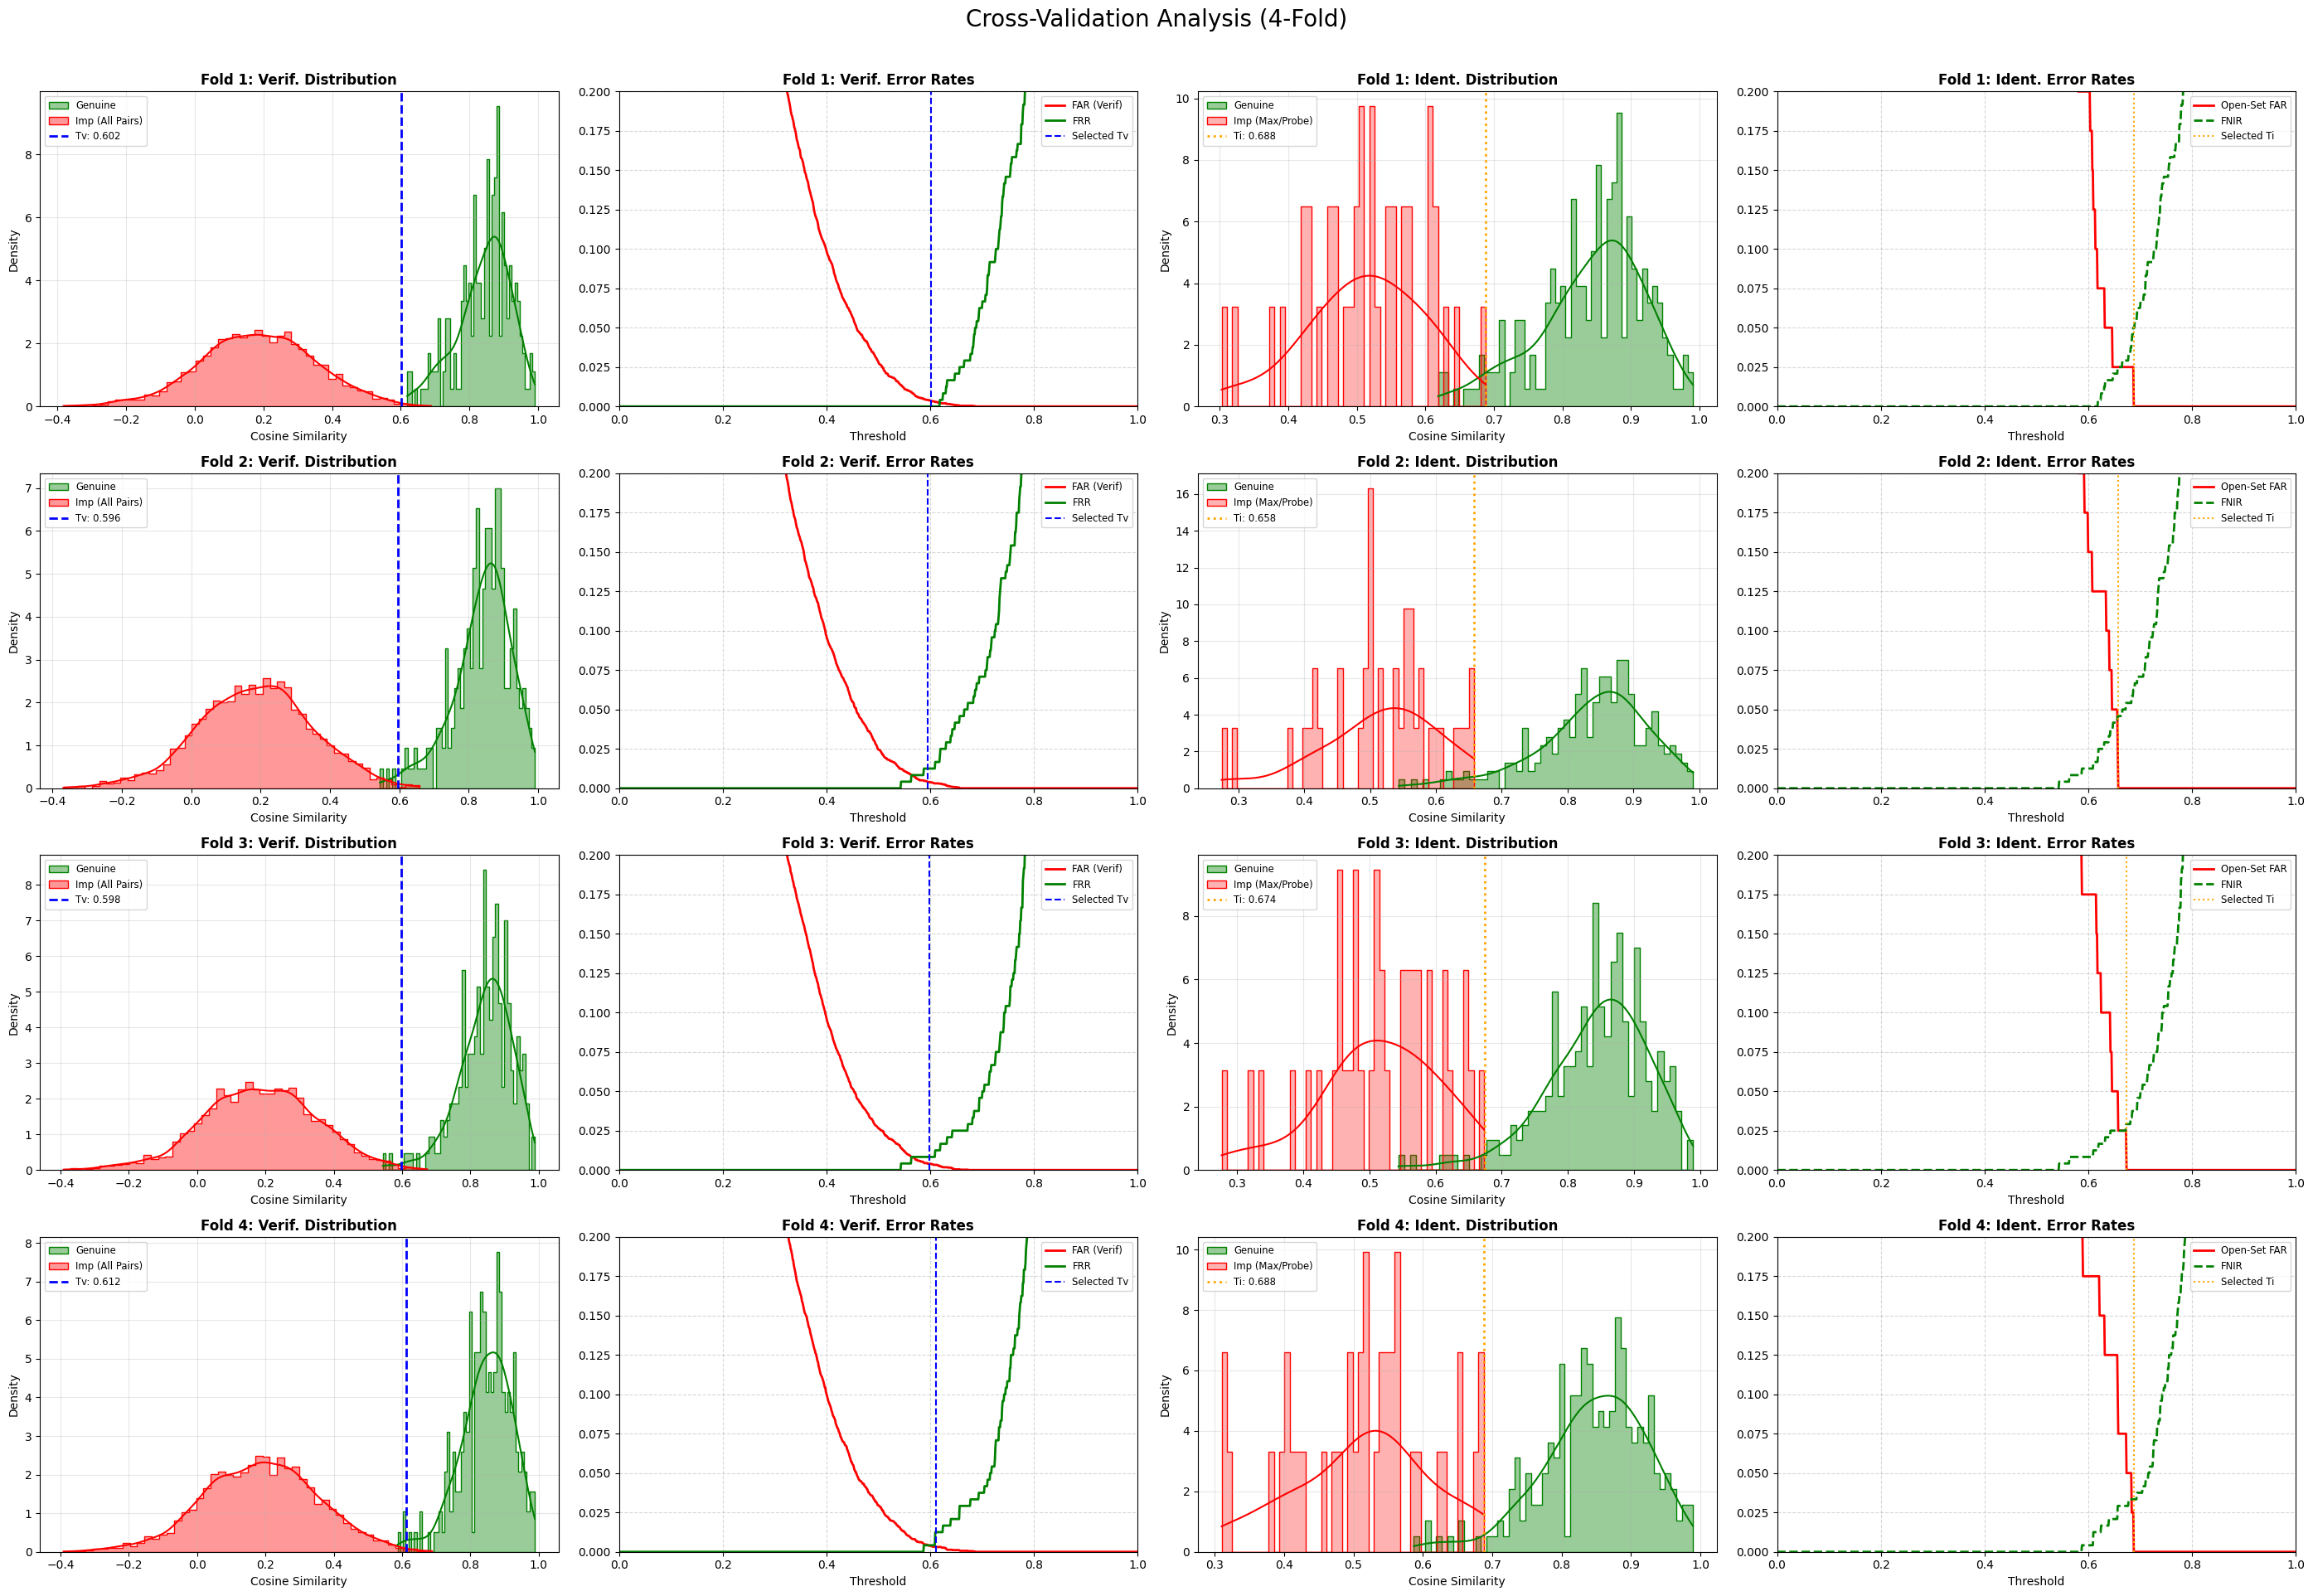


   CROSS-VALIDATION SUMMARY (Average across 4 folds)
Metric                         | Average    | Std Dev   
------------------------------------------------------------
Verification FAR (Tv)          | 0.36%     | ±0.04%
Verification FRR (Tv)          | 0.83%     | ±0.51%
------------------------------------------------------------
Identification Miss (FNIR)     | 0.00%     | ±0.00%
Open-Set FAR (Ti)              | 0.00%     | ±0.00%
Thresold tuning using K-FOLD cross-validation for validatiom:
K-FOLD RESULTS (Average of 4 runs)
Recommended Identification Threshold (Ti): 0.6770 with std: 0.0062
Recommended Verification Threshold (Tv): 0.6020 with std: 0.0124
CALCULATING FAR & FRR
Tv = 0.6080
--------------------------------------------------
Genuine Comparisons:  200
False Rejects:        0
--> FRR:              0.0000%
--------------------------------------------------
Impostor Comparisons: 3896
False Accepts:        12
--> FAR:              0.3080%

CALCULATING IDENTIFICATION METR

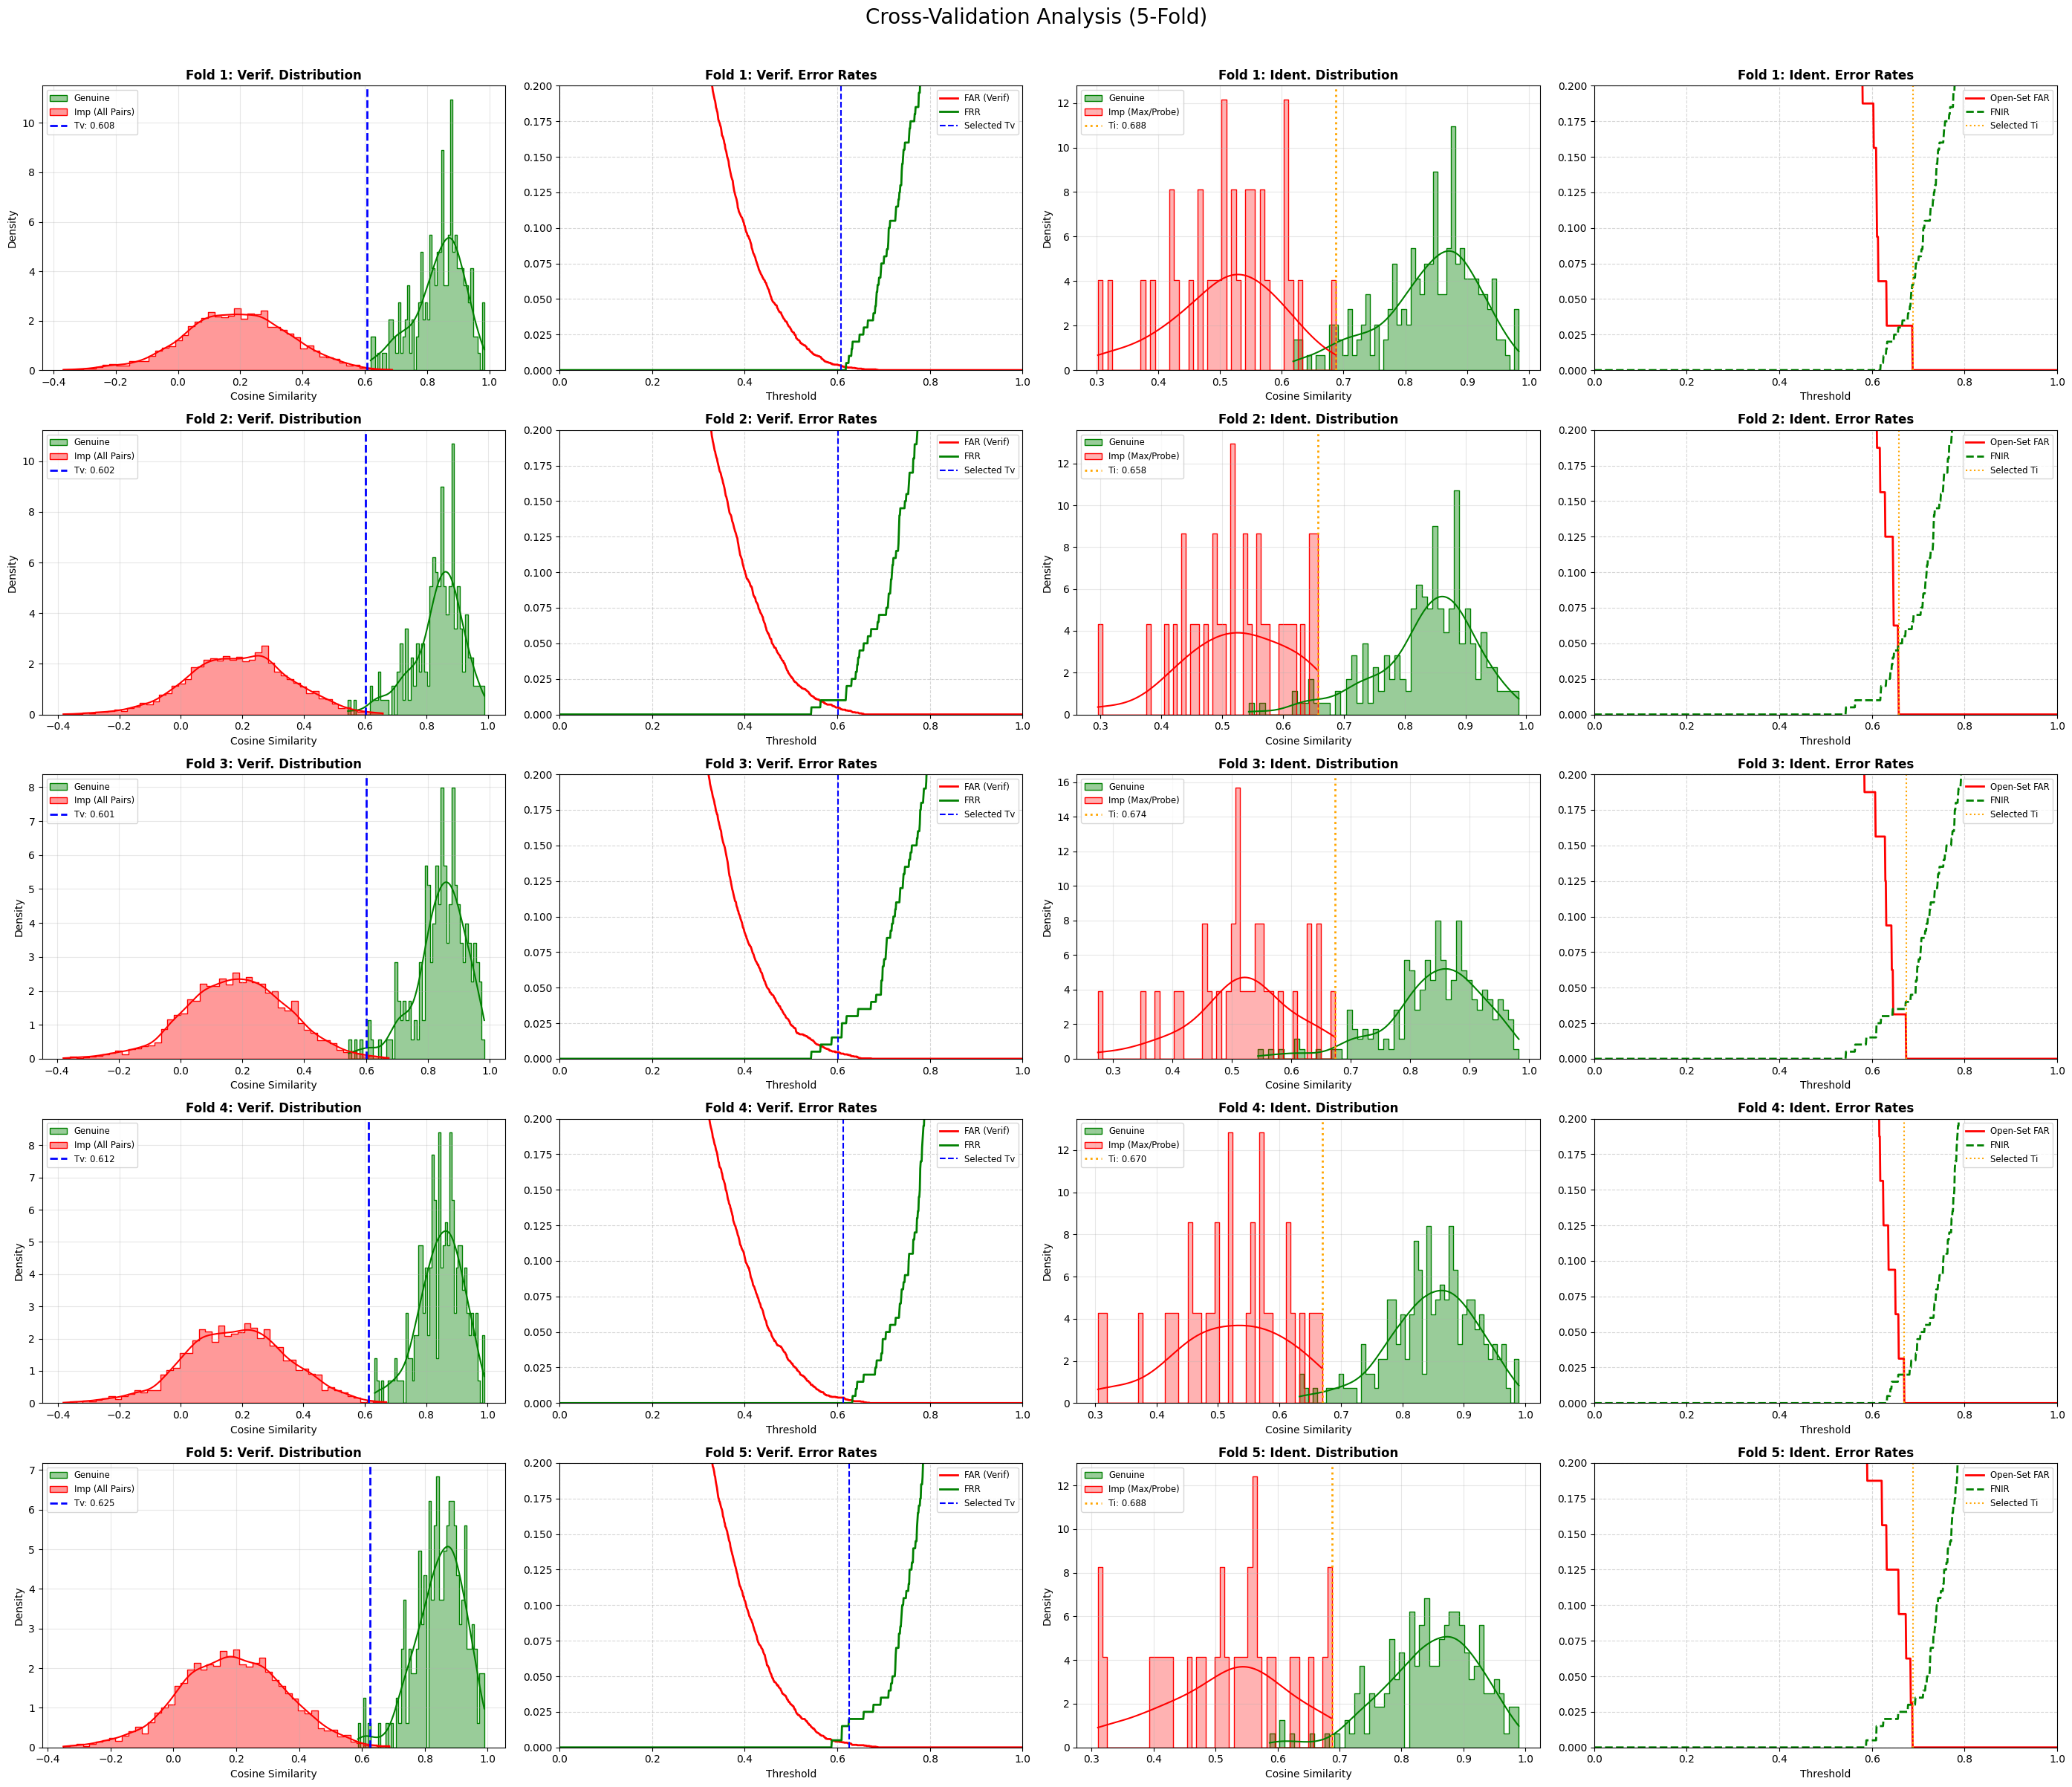


   CROSS-VALIDATION SUMMARY (Average across 5 folds)
Metric                         | Average    | Std Dev   
------------------------------------------------------------
Verification FAR (Tv)          | 0.39%     | ±0.08%
Verification FRR (Tv)          | 0.90%     | ±0.80%
------------------------------------------------------------
Identification Miss (FNIR)     | 0.00%     | ±0.00%
Open-Set FAR (Ti)              | 0.00%     | ±0.00%
Thresold tuning using K-FOLD cross-validation for validatiom:
K-FOLD RESULTS (Average of 5 runs)
Recommended Identification Threshold (Ti): 0.6756 with std: 0.0087
Recommended Verification Threshold (Tv): 0.6096 with std: 0.0114


In [66]:
step = 0.001             # threshold sweep resolution
desired_far = 0.001      # 0.1%
K = [3, 4, 5]
bias_ti = 0.0
bias_tv = -0.045         # makes Tv slightly more permissive (usability trade-off, see report Sec. 4.1.1)

# Thresholds are calibrated on the gallery only (image-disjoint stratified K-fold);
# results are returned as a dict so that Tv/Ti statistics cannot be swapped.
tuning_results = {}
for k in K:
    tuning_results[k] = th_tuning.find_optimal_thresholds_kfold(
        embeddings=best_X_train_norm, labels=best_y_train, k_folds=k, step=step, desired_far=desired_far,
        verbose=False, bias_ti=bias_ti, bias_tv=bias_tv, gal_names=gallery_names)

print(f"{'K':<3} | {'Tv':<8} | {'std Tv':<8} | {'Ti':<8} | {'std Ti':<8}")
for k, r in tuning_results.items():
    print(f"{k:<3} | {r['Tv']:.4f}   | {r['std_Tv']:.4f}   | {r['Ti']:.4f}   | {r['std_Ti']:.4f}")

# K=3 is selected: lowest error rates and most stable thresholds across folds (see report Sec. 4.2)
selected_k = 3

## Identification & Verification with Finetuned Thresholds

In the following section the finetuned thresholds will be tested with probes

Verification Threshold (Tv): 0.60130
Identification Threshold (Ti): 0.68330

CALCULATING FAR & FRR
Tv = 0.6013
--------------------------------------------------
Genuine Comparisons:  2880
False Rejects:        66
--> FRR:              2.2917%
--------------------------------------------------
Impostor Comparisons: 54720
False Accepts:        116
--> FAR:              0.2120%

CALCULATING IDENTIFICATION METRICS (1:N)
Threshold (Ti) = 0.6833
Total Probes: 360
Correct Identifications (DIR): 357
Misses (Unknown + Wrong ID):   3
--> Identification Rate (DIR): 99.17%
--> Miss Rate (FNIR):          0.83%

--- Running Open Set Simulation (Ti=0.6833) ---
Ti=0.6833:
  Total Impostor Attempts: 360
  False Acceptances:       3
  --> Open Set FAR:        0.8333%
--- Computing Score Distributions for Test Set ---


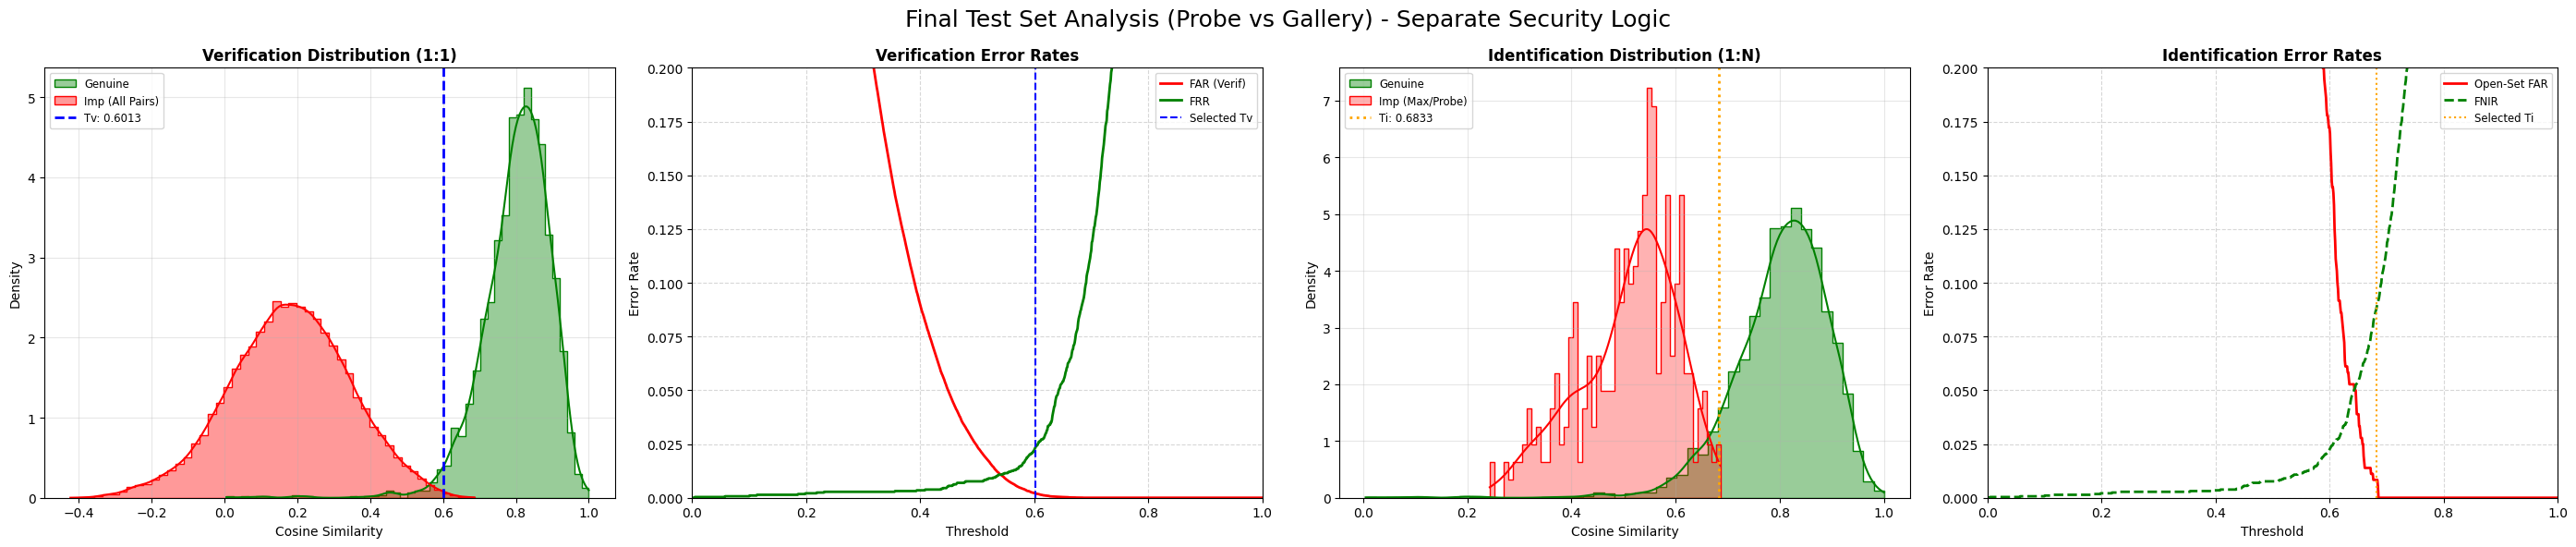

In [67]:
# Operating point selected above (K=3). Original run: Tv = 0.6013, Ti = 0.6833
finetuned_Tv = tuning_results[selected_k]["Tv"]
finetuned_Ti = tuning_results[selected_k]["Ti"]
print(f"Verification Threshold (Tv): {finetuned_Tv:.5f}")
print(f"Identification Threshold (Ti): {finetuned_Ti:.5f}\n")

# Load embedding gallery
gal_embs, gal_labels, gal_names = utils.load_gallery(filename=gallery_name, gallery_path=database_dir)

# FAR, FRR, FNIR are computed on the probe set (against the gallery)
v_far, v_frr = th_tuning.compute_far_frr_verification_on_probes(finetuned_Tv, best_probe_embs_norm, probe_labels, gal_embs, gal_labels)
i_fnir = th_tuning.compute_fnir_identification_on_probes(finetuned_Ti, best_probe_embs_norm, probe_labels, gal_embs, gal_labels, gal_names)
o_far = th_tuning.compute_open_set_far_on_probes(threshold=finetuned_Ti, probe_embs=best_probe_embs_norm, probe_labels=probe_labels, gal_embs=gal_embs, gal_labels=gal_labels, gal_names=gal_names)
# Plotting
th_tuning.plot_performance(best_probe_embs_norm, probe_labels, gal_embs, gal_labels, finetuned_Tv, finetuned_Ti)

## Download Liveness Dataset and Detect Faces

The dataset used for the liveness detection has been collected taking pictures of the screen with gallery and probes images displayed. 'Real' pictures are the orginal gallery and probes while the 'fake' ones are the pictures taken of the real ones.
In this section the dataset will be downloaded and the detector will be used to extract the cropped faces.

- Labeling: It has been Label 0 to fake folders and Label 1 to real folders.

- Flattening: It has been aggregated data from both galleries and probes for training. This maximizes the variety of examples the model sees.

In [68]:
os.makedirs(PROCESSED_DIR, exist_ok=True)
# File paths for cached datasets
train_cache = os.path.join(PROCESSED_DIR, "train_processed.pt")
val_cache   = os.path.join(PROCESSED_DIR, "val_processed.pt")
test_cache  = os.path.join(PROCESSED_DIR, "test_processed.pt")

if download_liveness_data_flag:
    liveness_train_data, liveness_validation_data, liveness_test_data, liveness_names = liveness_detector.download_liveness_dataset(DATA_DIR_LIVENESS_CUSTOM, liveness_train_ratio, liveness_val_ratio, liveness_test_ratio)
    if check_dataset_flag:
        print("\nSubject-Disjoint Split Complete.")
        print(f"liveness_train_data images shape: {liveness_train_data.images.shape}")  # (N, H, W, C)
        print(f"liveness_validation_data images shape: {liveness_validation_data.images.shape}")  # (N, H, W, C)
        print(f"liveness_test_data images shape: {liveness_test_data.images.shape}")  # (N, H, W, C)
        print(f"  Train: {len(liveness_train_data.images)} images ({len(liveness_train_data.subjects)} subjects)")
        print(f"  Val:   {len(liveness_validation_data.images)} images ({len(liveness_validation_data.subjects)} subjects)")
        print(f"  Test:  {len(liveness_test_data.images)} images ({len(liveness_test_data.subjects)} subjects)")
        
    # Detect faces in the liveness datasets
    processed_liveness_train = detector.detect_faces(liveness_train_data, method=detector_method, verbose=True, cnn=True)
    processed_liveness_val = detector.detect_faces(liveness_validation_data, method=detector_method, verbose=True, cnn=True)
    processed_liveness_test = detector.detect_faces(liveness_test_data, method=detector_method, verbose=True, cnn=True)
    
    # Save processed tensors to cache
    print(f"\n[CACHE] Saving processed tensors to {PROCESSED_DIR}...")
    torch.save(processed_liveness_train, train_cache)
    torch.save(processed_liveness_val,   val_cache)
    torch.save(processed_liveness_test,  test_cache)
    print(" -> Datasets saved successfully.")

# Load tensors from cache if available  
else:               
    if os.path.exists(train_cache) and os.path.exists(val_cache) and os.path.exists(test_cache):
        print(f"\n[CACHE] Loading processed tensors from {PROCESSED_DIR}...")
        try:
            # trusted local cache of Bunch objects -> full unpickling is required
            processed_liveness_train = torch.load(train_cache, weights_only=False)
            processed_liveness_val   = torch.load(val_cache, weights_only=False)
            processed_liveness_test  = torch.load(test_cache, weights_only=False)
            liveness_names = np.array(['Subject_00', 'Subject_01', 'Subject_02', 'Subject_03', 'Subject_04', 'Subject_05', 'Subject_06', 'Subject_07', 'Subject_08', 'Subject_09',
                                        'Subject_10', 'Subject_11', 'Subject_12', 'Subject_13', 'Subject_14', 'Subject_15', 'Subject_16', 'Subject_17', 'Subject_18', 'Subject_19'])
        except Exception as e:
            print(f"[ERROR] Cache load failed ({e}).")
            raise
    else:
        raise FileNotFoundError(f"Processed tensors not found in {PROCESSED_DIR}: set download_liveness_data_flag = True.")
    print(f"train_cache shape = {processed_liveness_train.images.shape}")
    print(f"val_cache shape = {processed_liveness_val.images.shape}")
    print(f"test_cache shape = {processed_liveness_test.images.shape}")

if visualize_detected_faces_flag:
    utils.visualize_detected_faces(processed_liveness_train, n_cols=25)
    utils.visualize_detected_faces(processed_liveness_val, n_cols=25)
    utils.visualize_detected_faces(processed_liveness_test, n_cols=25)

# Wrap the data to ensure compatibility (converts from Bunch to Dataset)
train_ds = liveness_detector.LivenessDatasetWrapper(processed_liveness_train)
val_ds   = liveness_detector.LivenessDatasetWrapper(processed_liveness_val)
test_ds  = liveness_detector.LivenessDatasetWrapper(processed_liveness_test)

# Create DataLoaders 
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False)

print(f"Training Batches: {len(train_loader)}")
print(f"Validation Batches: {len(val_loader)}")
print(f"Test Batches: {len(test_loader)}")
print(f"Subject names: {liveness_names}")
    


[CACHE] Loading processed tensors from .//Dataset//liveness_detection//Liveness_Dataset\processed_tensors...
train_cache shape = (620,)
val_cache shape = (208,)
test_cache shape = (208,)


Training Batches: 5
Validation Batches: 2
Test Batches: 2
Subject names: ['Subject_00' 'Subject_01' 'Subject_02' 'Subject_03' 'Subject_04'
 'Subject_05' 'Subject_06' 'Subject_07' 'Subject_08' 'Subject_09'
 'Subject_10' 'Subject_11' 'Subject_12' 'Subject_13' 'Subject_14'
 'Subject_15' 'Subject_16' 'Subject_17' 'Subject_18' 'Subject_19']


## Liveness Detector Training


#### Model Chosen
LivenessMobileNet has been chosen as the model for the liveness detection module

In [69]:
train_losses = []
val_losses = []
train_accs = []
val_accs = []
best_val_acc = 0.0
trigger_times = 0           # Counter for patience
min_val_loss = float('inf') # for early stopping 

if train_liveness_detector_flag:
    
    def train_one_epoch(loader):
        liveness_model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        for images, labels in loader:
            # Move to GPU
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1) # Reshape [N] -> [N, 1] for BCE
            optimizer.zero_grad()
            # Forward pass (Outputs are logits)
            outputs = liveness_model(images)
            loss = criterion(outputs, labels)
            # Backward pass
            loss.backward()
            optimizer.step()
            # Statistics
            running_loss += loss.item()
            # Calculate Accuracy (Sigmoid > 0.5 is equivalent to Logits > 0.0)
            predicted = (outputs > 0.0).float()
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
        return running_loss / len(loader), correct / total

    def validate(loader):
        liveness_model.eval()
        running_loss = 0.0
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in loader:
                images, labels = images.to(device), labels.to(device)
                labels = labels.float().unsqueeze(1)
                outputs = liveness_model(images)
                loss = criterion(outputs, labels)
                running_loss += loss.item()
                predicted = (outputs > 0.0).float()
                correct += (predicted == labels).sum().item()
                total += labels.size(0)
        return running_loss / len(loader), correct / total

    # Training Loop
    print(f"{'='*30}\nStarting Training for {liveness_epochs} Epochs\n{'='*30}")
    for epoch in range(liveness_epochs):
        train_loss, train_acc = train_one_epoch(train_loader)
        val_loss, val_acc = validate(val_loader)
        # Store stats
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accs.append(train_acc)
        val_accs.append(val_acc)
        # Print stats
        print(f"Epoch [{epoch+1}/{liveness_epochs}]")
        print(f"   Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.4f}%")
        print(f"   Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc*100:.4f}%")
        # 1. Save Best Model (Based on Accuracy)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(liveness_model.state_dict(), os.path.join(MODEL_DIR, liveness_model_name))
            print("   -> Liveness Model Saved (New Best Accuracy)!")

        # 2. Early Stopping Logic (Based on Loss)
        # It is standard to stop based on Loss (detects overfitting) rather than Accuracy
        if val_loss < min_val_loss:
            min_val_loss = val_loss
            trigger_times = 0  # Reset counter if performance improved
        else:
            trigger_times += 1
            print(f"   -> No improvement in Validation Loss. Patience: {trigger_times}/{liveness_patience}")
            
            if trigger_times >= liveness_patience:
                print(f"\n[!] Early Stopping Triggered at Epoch {epoch+1}")
                print(f"    Validation Loss did not decrease for {liveness_patience} epochs.")
                break

    print(f"\nTraining Complete. Best Validation Accuracy: {best_val_acc*100:.4f}%")
    # Plot training stats
    plt.figure(figsize=(12, 5))
    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss', color='blue', marker='o')
    plt.plot(val_losses, label='Val Loss', color='red', marker='x')
    plt.title('Training vs Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    # Plot Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(train_accs, label='Train Accuracy', color='blue', marker='o')
    plt.plot(val_accs, label='Val Accuracy', color='red', marker='x')
    plt.title('Training vs Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    # Load the best liveness_model
    liveness_model.load_state_dict(torch.load(os.path.join(MODEL_DIR, liveness_model_name), weights_only=True))
    test_loss, test_acc = validate(test_loader)
    print(f"{'='*30}")
    print(f"FINAL TEST RESULT")
    print(f"{'='*30}")
    print(f"Test Accuracy: {test_acc*100:.4f}%")
    
else: 
    liveness_model_dir =  os.path.exists(os.path.join(MODEL_DIR, liveness_model_name))
    if liveness_model_dir:
        print(f"Loading model from: {os.path.join(MODEL_DIR, liveness_model_name)}")
        liveness_model.load_state_dict(torch.load(os.path.join(MODEL_DIR, liveness_model_name), weights_only=True))
        print(f"Best Liveness Detection liveness_Model loaded from '{liveness_model_name}'")
    else:
        print("No trained liveness detection liveness_model found.")

Loading model from: .//Models\liveness_model.pth
Best Liveness Detection liveness_Model loaded from 'liveness_model.pth'


## Threshold Tuning $\tau_f$ 

This section details the determination of optimal values for the fake threshold ($\tau_f$) , aimed at implementing system requirement 5.

To determine the optimal decision threshold ($T_f$) for the liveness detector, the Equal Error Rate (EER) strategy was initially considered. This methodology involves analyzing the Receiver Operating Characteristic (ROC) curve to identify the specific probability threshold where the False Live Rate (FLR) approximates the False Fake Rate (FFR). Theoretically, this point offers the most balanced trade-off between security (blocking fakes) and usability (accepting real users).

However, an analysis of the model's probability outputs on the validation set revealed an exceptionally clear separation between the two classes. The model assigns probability scores that are consistently clustered near 0.0 for spoofing attacks and near 1.0 for live presentations, with virtually no overlap. Given this high degree of separation and the near-perfect accuracy observed during validation, fine-tuning the threshold to the exact EER point offered no statistically significant advantage over the standard default. Consequently, a natural decision threshold of $T_f = 0.5$ was adopted. 






Evaluating Liveness Detector on Validation Set with Base Threshold (Tf=0.5)...
Evaluating Liveness Detector on Validation Set with Base Threshold...


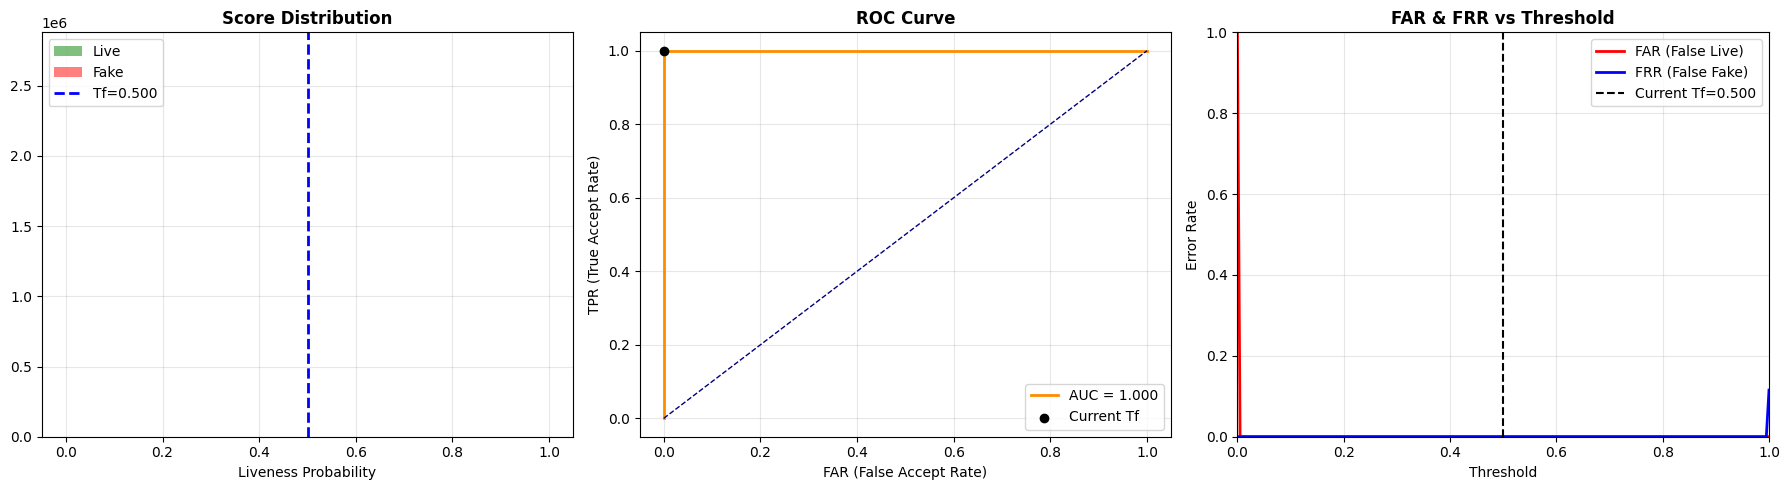

----------------------------------------
LIVENESS STATS (Tf=0.5000)
----------------------------------------
Accuracy:          100.000%
False Live Rate:   0.000%
False Fake Rate:   0.000%
Average Error:     0.000%
----------------------------------------
classification probabilities: [0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.001
 0.004 0.    0.    0.    0.    0.    0.    0.    1.    1.    1.    1.
 1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.
 1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.
 1.    1.    1.    1.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.001 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.  

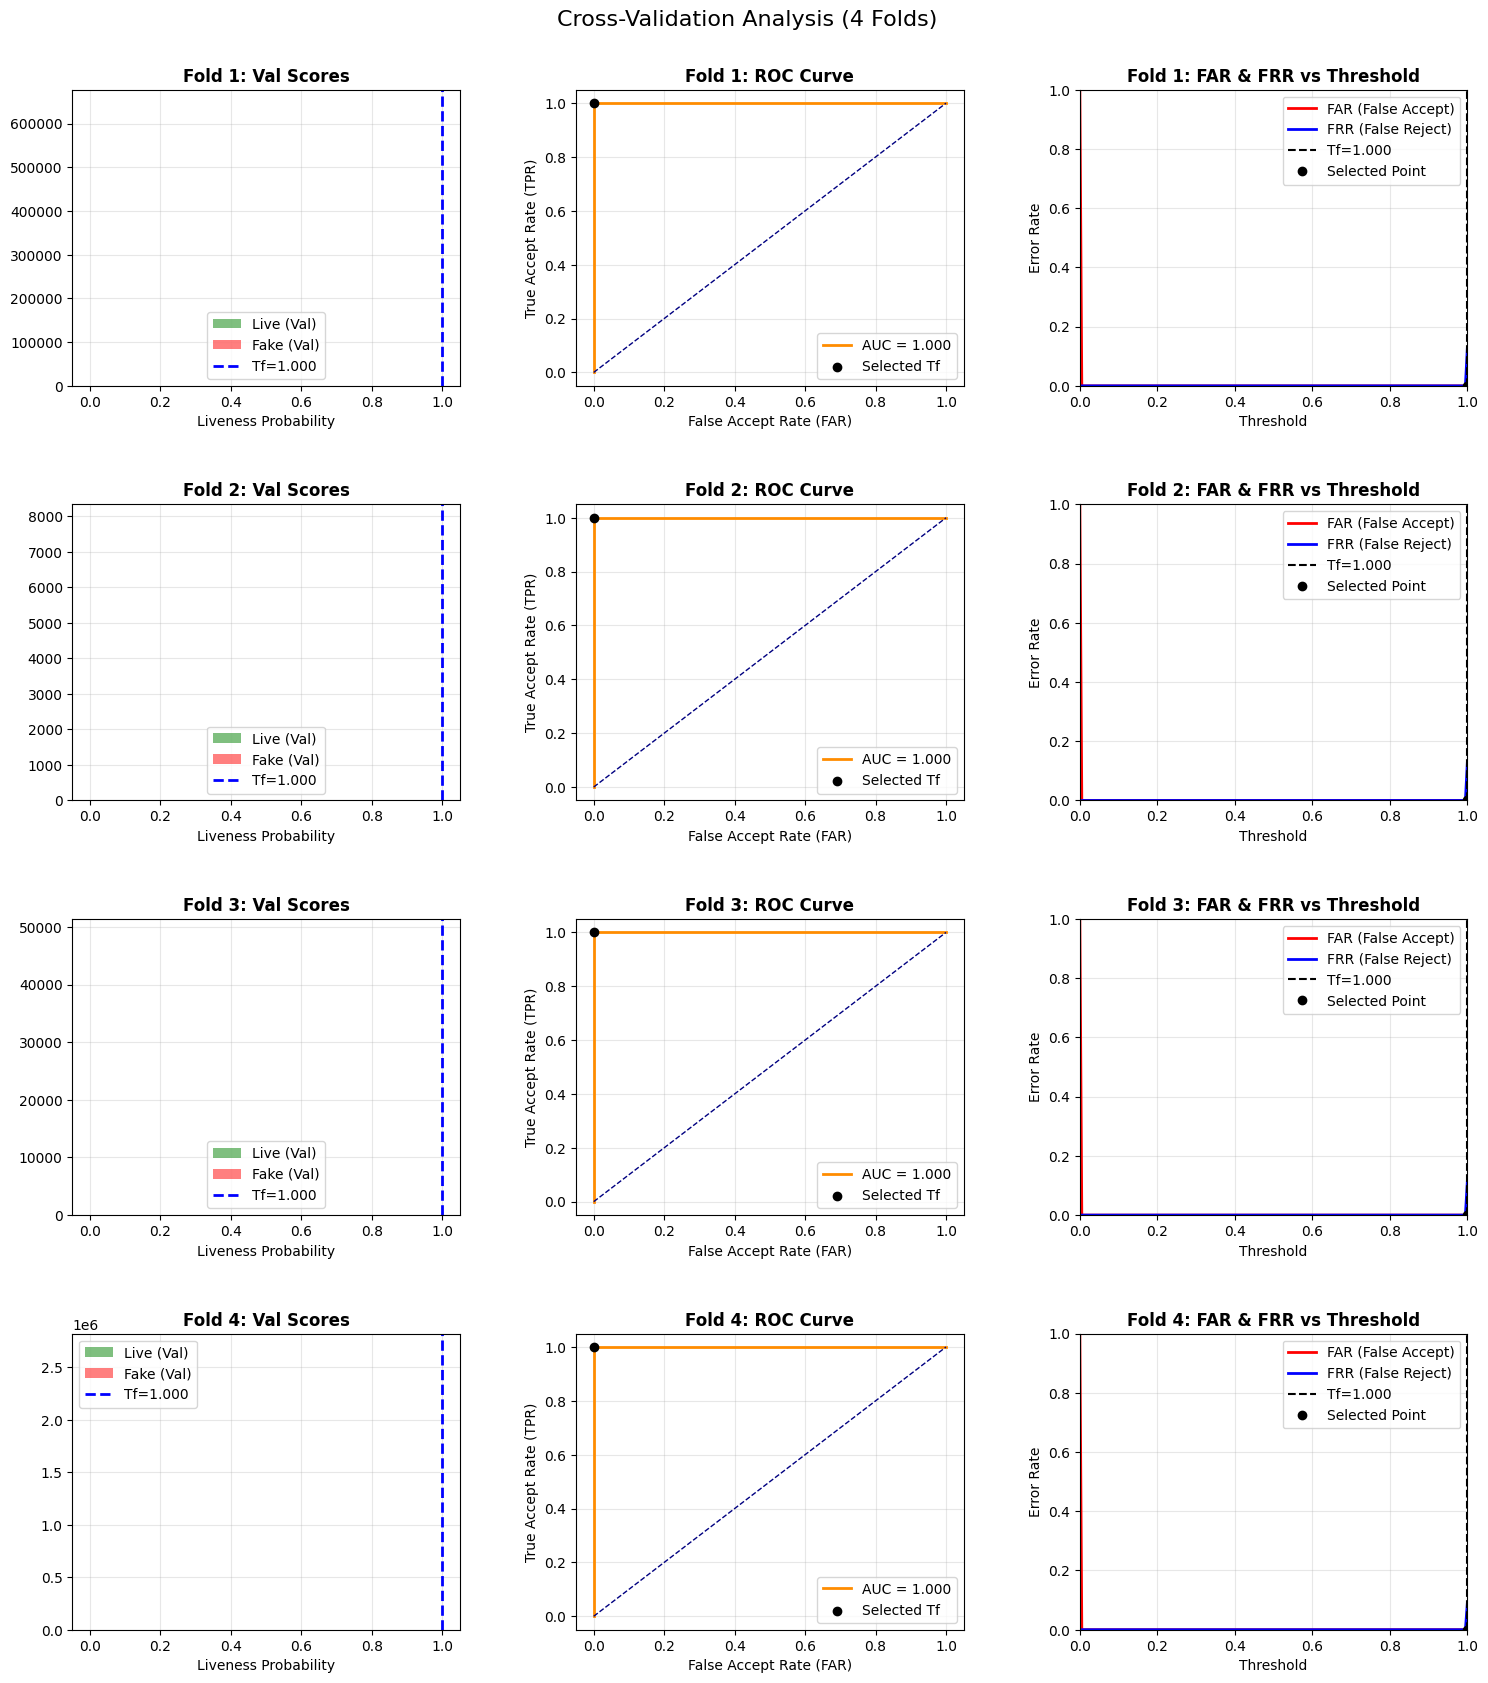


FINAL RESULT (4-Fold CV)
Thresholds found: ['1.0000', '1.0000', '1.0000', '1.0000']
Average Threshold: 1.0000 (+/- 0.0000)

Optimal Tuned Threshold (EER): 1.0000


In [70]:
base_Tf = 0.5
# Evaluate on validation set with base threshold
print(f"\n\n{'='*150}\n{'='*150}\n\n")
print(f"\nEvaluating Liveness Detector on Validation Set with Base Threshold (Tf={base_Tf})...")
print("Evaluating Liveness Detector on Validation Set with Base Threshold...")
probs, labels, _, _ = liveness_detector.evaluate_liveness(val_loader, liveness_model, device, base_Tf)
print(f"classification probabilities: {np.round(probs, 3)}")


print(f"\n\n{'='*150}\n{'='*150}\n\n")
# Find a better threshold using K-Fold cross-validation on validation set
print(f"\nFinding optimal threshold using K-Fold cross-validation on Validation Set...")
finetuned_Tf = th_tuning.compute_liveness_threshold_kfold(labels, probs)
print(f"\nOptimal Tuned Threshold (EER): {finetuned_Tf:.4f}")

## Liveness with Finetuned Thresholds

In the following section the finetuned thresholds will be tested on the test set (20% of the orginal data split on the liveness dataset)

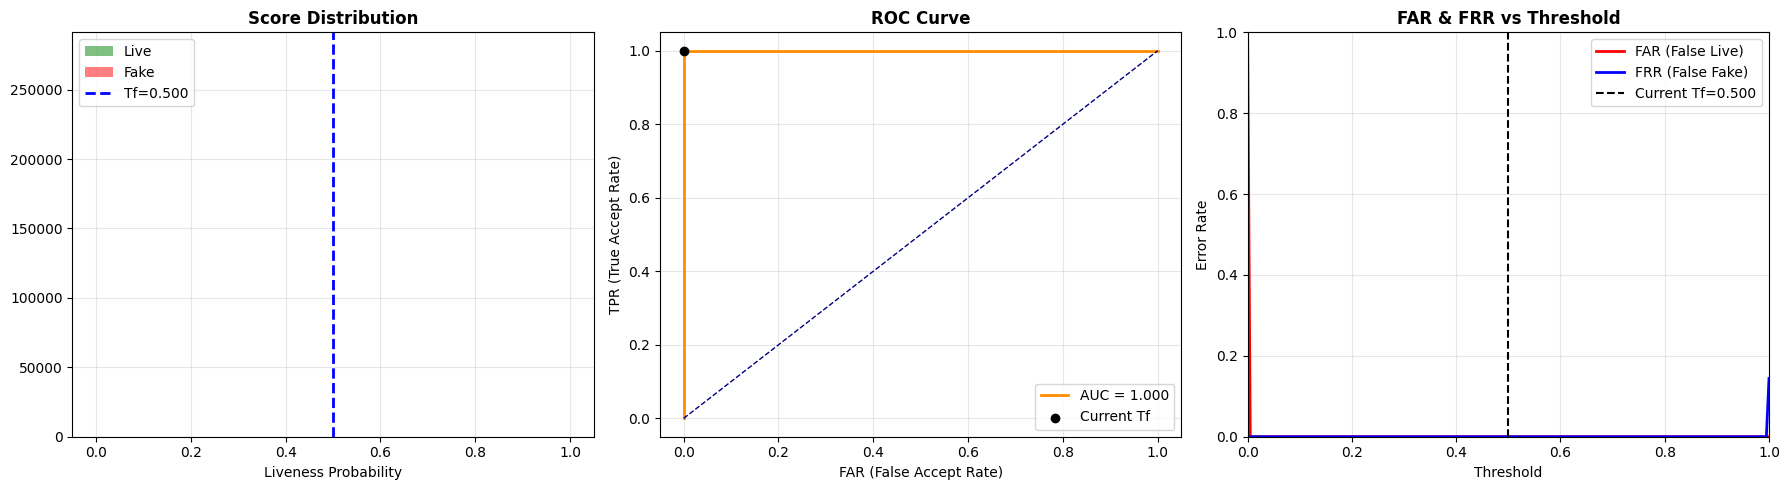

----------------------------------------
LIVENESS STATS (Tf=0.5000)
----------------------------------------
Accuracy:          100.000%
False Live Rate:   0.000%
False Fake Rate:   0.000%
Average Error:     0.000%
----------------------------------------

Test set raw probabilities with Tf=0.5:
[0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.001
 0.    0.    0.    0.    0.    0.    0.    0.    1.    1.    1.    1.
 1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.
 1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.
 1.    1.    1.    1.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.    0.    0.002 0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.


In [71]:
probs, labels, _, _ = liveness_detector.evaluate_liveness(test_loader, liveness_model, device, base_Tf)
all_probs_rounded = np.round(probs, 3)
print(f"\nTest set raw probabilities with Tf=0.5:\n{all_probs_rounded}")

Tf = 0.5        # Chosen threshold

## Face Quality Threshold Tunining

### Methodology: Determination of Optimal Face Quality Threshold

> **Protocol:** the threshold is calibrated on the **gallery only** with a 4-fold cross-validated ERC (the held-out gallery fold plays the role of the probes). The probe set is used once, afterwards, to measure the effect of the quality gate on unseen data.

To scientifically select a valid quality threshold for the biometric system, the Error vs. Reject Characteristic (ERC) analysis was employed. Unlike standard performance metrics that evaluate a static dataset, this method evaluates how the performance of the face recognition system improves as low-quality images are progressively discarded from the verification stream. Particularly the method implemented decouples the assessment of quality from the verification capability, allowing the system to leverage the specific strengths of two distinct models:

1. Quality Assessor (MagFace): Used solely to quantify the "utility" of a face image based on its geometric alignment and clarity.

2. Recognition Engine (Main Pipeline): Used to compute the actual identity embeddings, ensuring the threshold is tuned to the real-world performance of the production model.



### Data Preparation & Processing

The evaluation utilized a Gallery vs. Probe protocol to mirror operational deployment:

- Gallery Set: The provided images acting as the system gallery.

- Probe Set: Images representing real-world verification attempts, subject to quality filtering.

Each image within both sets underwent the following pipeline:

- Alignment: Using MTCNN, facial landmarks (eyes, nose, mouth) were detected, and the face was warped to a standard 112×112 coordinate system based on 5-point landmarks. This ensures the MagFace network receives the precise geometric input for which it was optimized. Consequently tandard cropping/preprocessing required by the main recognition model (for embedding generation) has been implemented.

- Feature Extraction: 
    - The MagFace model was utilized to simultaneously extract the magnitude (norm) of the embedding vector, serving as the quantitative metric.
    - The main recognition model (best_model_name = InceptionResnetV1-VGGFace2) eas used to extract the features to ensure the error rates calculated during tuning match the actual system accuracy.


### Simulation of Rejection (ERC Protocol)

The entire Probe dataset is sorted in ascending order based on the MagFace Quality Score to group all the igh risk images at the beginning of the array. 
- Ranking: The Probe dataset was sorted by MagFace quality score in ascending order.
- Fine-Grained Pruning: The system iteratively simulates a stricter quality gate by removing the bottom $N\%$ of Probe images were progressively removed in 1% increments (from 0% to 50%).  At each step $R$, the bottom $R\%$ of images are discarded and temporary subset of "Surviving Probes" is created, containing only the top $(100-R)\%$ of images.
- Verification Test: For each subset of surviving Probes, the False Non-Match Rate (FNMR) was calculated by matching The main model embeddings (InceptionResnetV1-VGGFace2) of the surviving probes are compared against the fixed Gallery embeddings. The system counts how many genuine pairs (Probe $X$ vs. Gallery $X$) fail to meet the required security similarity threshold: 

$$\text{FNMR}_R = \frac{\text{Number of Failed Genuine Matches}}{\text{Total Number of Genuine Pairs in Subset}_R}$$

As $R$ increases, the "bad" images (which generate the failures) are removed from the subset. Consequently, the numerator (Failed Matches) decreases faster than the denominator, causing the overall FNMR to drop.


### Determination of the Optimal Threshold
Determination of the Optimal Threshold The optimization of the face quality threshold is conducted via an Adaptive Anchor with Local Refinement protocol. This methodology addresses the critical trade-off between system throughput (low rejection) and input fidelity (high quality) by strictly sequencing the selection criteria:

- Anchor Identification (Baseline Efficiency): The algorithm first identifies the "Permissive Anchor," defined as the lowest rejection ratio capable of satisfying the system's error target (e.g., FNMR $\approx$ 1.0%). This step establishes a baseline solution that prioritizes minimizing user impact.

- Local Refinement (Quality Maximization): Originating from this anchor, the system scans the adjacent operational space (bounded by a 30% hard limit) to identify alternative operating points.

- Selection Logic: The algorithm isolates all candidate points that exhibit an error rate statistically equivalent to the anchor (Stability Check). From this subset, it selects the candidate corresponding to the highest MagFace Quality Score

- Below Threshold: Images are classified as "low-utility noise," where the Recognition Engine is statistically demonstrated to exhibit high failure rates.

- Above Threshold: Images are verified to possess sufficient geometric clarity to maximize feature extraction performance.

This approach ensures the quality gate is perfectly calibrated to the recognition model's capability, extracting the maximum possible security performance without violating operational service-level agreements regarding user rejection.


--- Hybrid Threshold Evaluation (Pre-computed Embeddings) ---
Gallery Images: 160 | Embeddings: (160, 512)
Probe Images:   360 | Embeddings: (360, 512)

>>> Processing Gallery...
[Gallery] Processing 30/160 - Avg Quality (last 30 samples): 23.73
[Gallery] Processing 60/160 - Avg Quality (last 30 samples): 25.47
[Gallery] Processing 90/160 - Avg Quality (last 30 samples): 24.02
[Gallery] Processing 120/160 - Avg Quality (last 30 samples): 24.90
[Gallery] Processing 150/160 - Avg Quality (last 30 samples): 24.50

[Gallery] Completed. Valid pairs: 160/160
Filtered Gallery: 160 images 

>>> Processing Probe...
[Probe] Processing 30/360 - Avg Quality (last 30 samples): 24.82
[Probe] Processing 60/360 - Avg Quality (last 30 samples): 24.33
[Probe] Processing 90/360 - Avg Quality (last 30 samples): 24.47
[Probe] Processing 120/360 - Avg Quality (last 30 samples): 23.09
[Probe] Processing 150/360 - Avg Quality (last 30 samples): 24.20
[Probe] Processing 180/360 - Avg Quality (last 30 samples)

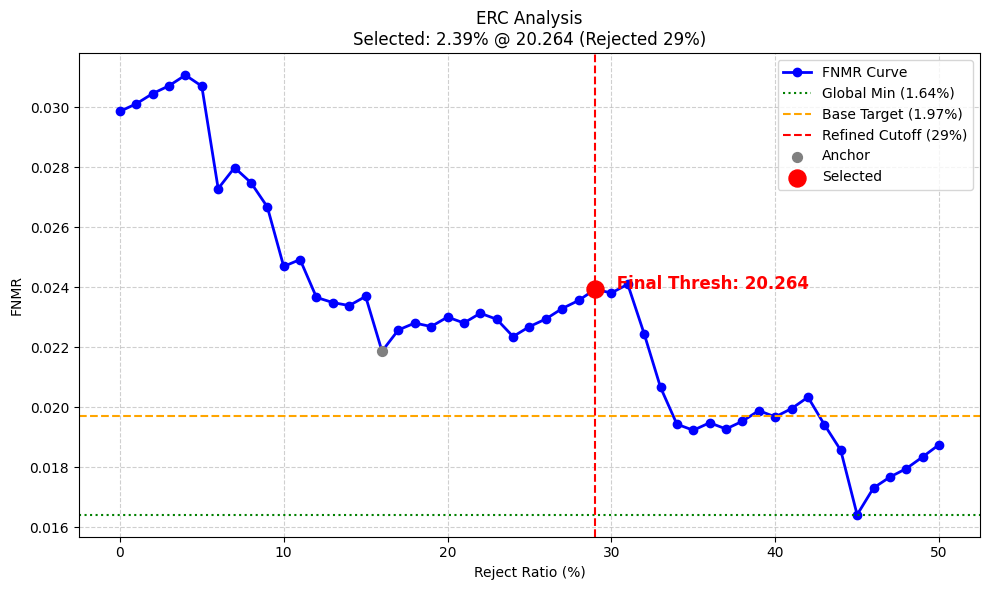


Optimal Quality Threshold determined: 20.2637
Reject Ratio: 29.00%
FNMR: 2.3926%)


In [72]:
from sklearn.utils import Bunch

target_fmr = 0.001
# File paths aligned 1:1 with the gallery / probe embeddings (images without a detected face are excluded)
gallery_files = Bunch(images=processed_train.paths, target=processed_train.target)
probe_files = Bunch(images=processed_test.paths, target=processed_test.target)

# 1. Calibration on the gallery only (4-fold cross-validated ERC)
#    refine_tolerance is an ABSOLUTE FNMR tolerance: 0.05 = +5 percentage points w.r.t. the anchor
face_quality_th = face_quality.compute_magface_threshold(
    magface=magface, gallery_data=gallery_files, gallery_embeddings=gal_embs, device=device,
    k_folds=4, target_fmr=target_fmr, refine_tolerance=0.05)

# 2. Assessment on the probes (test set)
quality_results = face_quality.evaluate_quality_threshold_on_probes(
    magface, gallery_data=gallery_files, gallery_embeddings=gal_embs, probe_data=probe_files,
    probe_embeddings=best_probe_embs_norm, device=device, quality_threshold=face_quality_th, target_fmr=target_fmr)

## Performance Evaluation

In this section a final system test with performance evaluation is performed 

FINAL SYSTEM PERFORMANCE EVALUATION
--- EVALUATING RANK-1 ---

==================== PERFORMANCE REPORT (Rank-1) ====================
[FALSE REJECT] Probe 134 (subject_07) found at Rank-1 but Score 0.6766 < Threshold 0.6833
[FALSE REJECT] Probe 345 (subject_19) found at Rank-1 but Score 0.5128 < Threshold 0.6833
------------------------------------------------------------
Rank-1 Accuracy: 99.17%
False Rejection Rate (FRR): 0.83%
False Acceptance Rate (FAR): 0.00%

--- EVALUATING RANK-2 ---

==================== PERFORMANCE REPORT (Rank-2) ====================
[FALSE REJECT] Probe 134 (subject_07) found at Rank-1 but Score 0.6766 < Threshold 0.6833
[FALSE REJECT] Probe 345 (subject_19) found at Rank-1 but Score 0.5128 < Threshold 0.6833
------------------------------------------------------------
Rank-2 Accuracy: 99.17%
False Rejection Rate (FRR): 0.83%
False Acceptance Rate (FAR): 0.00%



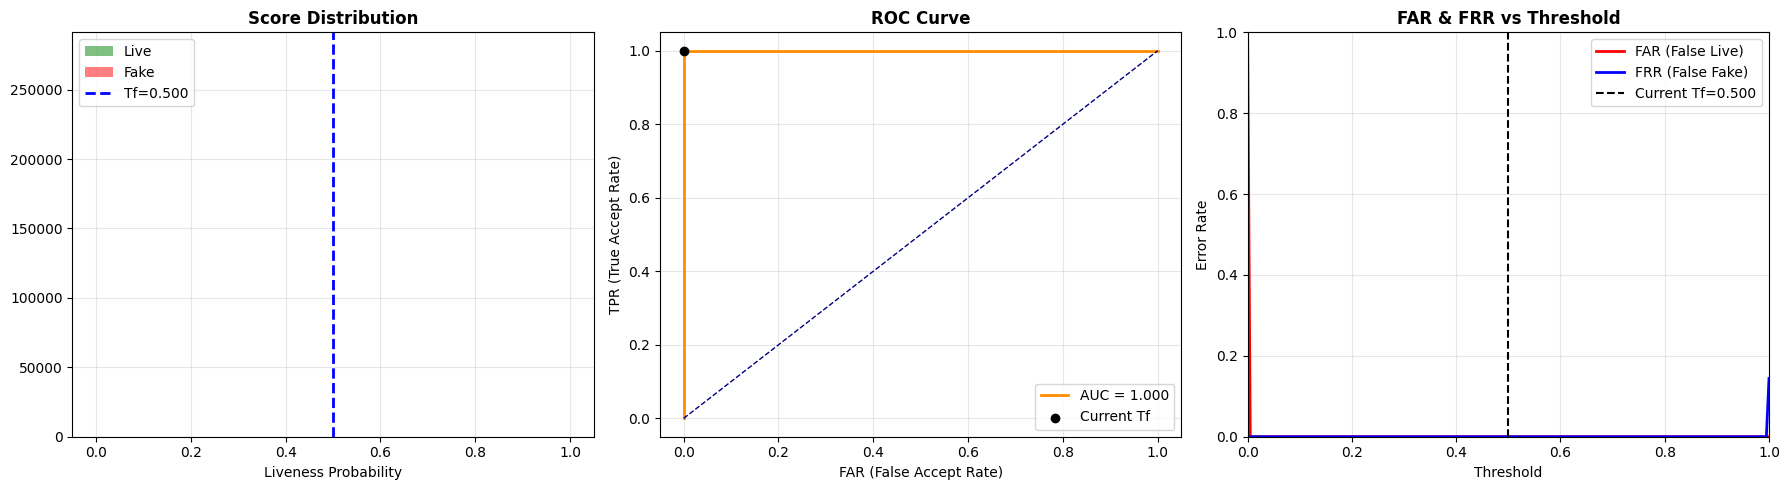

----------------------------------------
LIVENESS STATS (Tf=0.5000)
----------------------------------------
Accuracy:          100.000%
False Live Rate:   0.000%
False Fake Rate:   0.000%
Average Error:     0.000%
----------------------------------------


In [73]:
print(f"{'='*40}")
print(f"FINAL SYSTEM PERFORMANCE EVALUATION")
print(f"{'='*40}")

# ------------------------------------------
# 2. EVALUATE FACE RECOGNITION (Rank-N & FRR)
# ------------------------------------------
print("--- EVALUATING RANK-1 ---")
acc_r1, frr_r1, far_r1 = utils.evaluate_rank_n_performance(gal_embs, gal_labels, best_probe_embs_norm, probe_labels, threshold=finetuned_Ti, rank=1, gallery_names=gallery_names)
print("--- EVALUATING RANK-2 ---")
acc_r2, frr_r2, far_r2 = utils.evaluate_rank_n_performance(gal_embs, gal_labels, best_probe_embs_norm, probe_labels, threshold=finetuned_Ti, rank=2, gallery_names=gallery_names)

# 3. Replay Attack FAR (Rank-1)
probs, labels, _, _ = liveness_detector.evaluate_liveness(test_loader, liveness_model, device, Tf)